# PharmaPrice Intelligence
## 1. Project Setup and Data Loading

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("indian_pharmaceutical_products_clean.csv")

In [4]:
df.head()

,product_id,brand_name,manufacturer,price_inr,is_discontinued,dosage_form,pack_size,pack_unit,num_active_ingredients,primary_ingredient,primary_strength,active_ingredients,therapeutic_class,packaging_raw,manufacturer_raw
0,1,Augmentin 625 Duo Tablet,Glaxo SmithKline Pharmaceuticals Ltd,223.42,False,tablet,10.0,strip,2,Amoxycillin,500mg,"[{'name': 'Amoxycillin', 'strength': '500mg', ...",antibiotic,strip of 10 tablets,Glaxo SmithKline Pharmaceuticals Ltd
1,2,Azithral 500 Tablet,Alembic Pharmaceuticals Ltd,132.36,False,tablet,5.0,strip,1,Azithromycin,500mg,"[{'name': 'Azithromycin', 'strength': '500mg',...",antibiotic,strip of 5 tablets,Alembic Pharmaceuticals Ltd
2,3,Ascoril LS Syrup,Glenmark Pharmaceuticals Ltd,118.00,False,syrup,100.0,bottle,2,Ambroxol,30mg/5ml,"[{'name': 'Ambroxol', 'strength': '30mg/5ml', ...",bronchodilator,bottle of 100 ml Syrup,Glenmark Pharmaceuticals Ltd
3,4,Allegra 120mg Tablet,Sanofi India Ltd,218.81,False,tablet,10.0,strip,1,Fexofenadine,120mg,"[{'name': 'Fexofenadine', 'strength': '120mg',...",antihistamine,strip of 10 tablets,Sanofi India Ltd
4,5,Avil 25 Tablet,Sanofi India Ltd,10.96,False,tablet,15.0,strip,1,Pheniramine,25mg,"[{'name': 'Pheniramine', 'strength': '25mg', '...",other,strip of 15 tablets,Sanofi India Ltd


In [5]:
df.shape

(253973, 15)

In [6]:
df.isna().sum()

product_id                    0
brand_name                    0
manufacturer                  0
price_inr                     0
is_discontinued               0
dosage_form                   0
pack_size                 22330
pack_unit                 22330
num_active_ingredients        0
primary_ingredient            0
primary_strength          25198
active_ingredients            0
therapeutic_class             0
packaging_raw                 0
manufacturer_raw              0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253973 entries, 0 to 253972
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   product_id              253973 non-null  int64  
 1   brand_name              253973 non-null  str    
 2   manufacturer            253973 non-null  str    
 3   price_inr               253973 non-null  float64
 4   is_discontinued         253973 non-null  bool   
 5   dosage_form             253973 non-null  str    
 6   pack_size               231643 non-null  float64
 7   pack_unit               231643 non-null  str    
 8   num_active_ingredients  253973 non-null  int64  
 9   primary_ingredient      253973 non-null  str    
 10  primary_strength        228775 non-null  str    
 11  active_ingredients      253973 non-null  str    
 12  therapeutic_class       253973 non-null  str    
 13  packaging_raw           253973 non-null  str    
 14  manufacturer_raw        253973 

In [9]:
df.nunique()

product_id                253973
brand_name                249398
manufacturer                7648
price_inr                  20664
is_discontinued                2
dosage_form                   15
pack_size                     91
pack_unit                      6
num_active_ingredients         5
primary_ingredient          1586
primary_strength             673
active_ingredients         11802
therapeutic_class             11
packaging_raw               1929
manufacturer_raw            7648
dtype: int64

In [10]:
df.describe()

,product_id,price_inr,pack_size,num_active_ingredients
count,253973.000000,253973.000000,231643.000000,253973.000000
mean,126987.000000,270.530844,18.988871,1.441893
std,73315.834296,3029.584134,36.717320,0.496795
min,1.000000,0.000000,1.000000,1.000000
25%,63494.000000,48.000000,10.000000,1.000000
50%,126987.000000,79.000000,10.000000,1.000000
75%,190480.000000,140.000000,10.000000,2.000000
max,253973.000000,436000.000000,5000.000000,5.000000


### Numerical and categorical columns

In [11]:
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns
print("Numerical Columns:", list(numerical_cols))
print("Categorical Columns:", list(categorical_cols))


Numerical Columns: ['product_id', 'price_inr', 'pack_size', 'num_active_ingredients']
Categorical Columns: ['brand_name', 'manufacturer', 'dosage_form', 'pack_unit', 'primary_ingredient', 'primary_strength', 'active_ingredients', 'therapeutic_class', 'packaging_raw', 'manufacturer_raw']


### Price analysis

In [12]:
df["price_inr"].describe()

count    253973.000000
mean        270.530844
std        3029.584134
min           0.000000
25%          48.000000
50%          79.000000
75%         140.000000
max      436000.000000
Name: price_inr, dtype: float64

In [13]:
print("Skewness:", df["price_inr"].skew())
print("Kurtosis:", df["price_inr"].kurt())

Skewness: 68.19084483249648
Kurtosis: 6709.382367982662


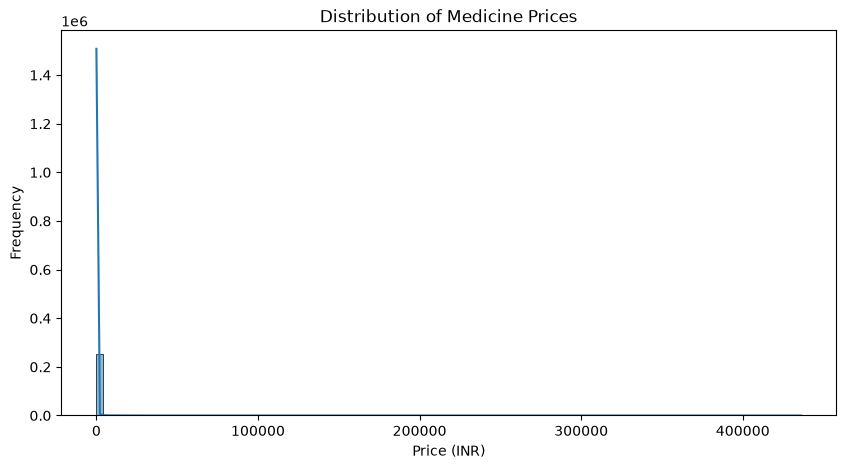

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(df["price_inr"], bins=100, kde=True)

plt.title("Distribution of Medicine Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Frequency")

plt.show()

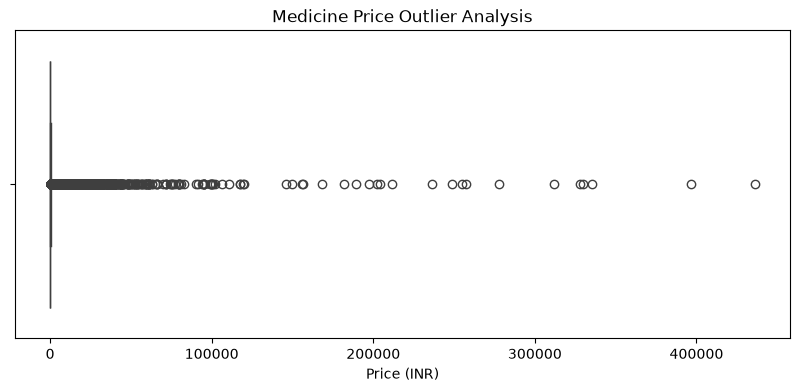

In [15]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["price_inr"])

plt.title("Medicine Price Outlier Analysis")
plt.xlabel("Price (INR)")

plt.show()

In [16]:
df["price_inr"].quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1])

0.000         0.00
0.250        48.00
0.500        79.00
0.750       140.00
0.900       254.00
0.950       430.50
0.990      2899.28
0.999     26593.08
1.000    436000.00
Name: price_inr, dtype: float64

Our pharmaceutical price distribution is highly imbalanced in terms of price ranges.

#### Investigate expensive medicines

In [17]:
expensive_medicines = df.nlargest(20,"price_inr")
print(
    expensive_medicines[
        ["brand_name", "manufacturer",
         "price_inr", "dosage_form"]
    ].to_string(index=False)
)

                          brand_name                         manufacturer  price_inr dosage_form
             Imbruvica 140mg Capsule              Janssen Pharmaceuticals  436000.00     capsule
          Tecentriq 1200mg Injection         Roche Products India Pvt Ltd  396725.00    solution
            Xtandi 40mg Soft Capsule                  Astellas Pharma Inc  335635.00     capsule
              Besponsa 1mg Injection                           Pfizer Ltd  330000.00   injection
             Imbruvica 140mg Capsule              Janssen Pharmaceuticals  328000.00     capsule
              Lorbriqua 100mg Tablet                           Pfizer Ltd  312000.00      tablet
                 Tecentriq Injection         Roche Products India Pvt Ltd  277708.00   injection
             Cyramza 500mg Injection  Eli Lilly and Company India Pvt Ltd  257532.00   injection
             Perjeta 420mg Injection         Roche Products India Pvt Ltd  255150.00   injection
             Kadcyla 160mg Inj

In [18]:
df[df["price_inr"]==0][["brand_name", "manufacturer", "dosage_form"]]

,brand_name,manufacturer,dosage_form
35090,Covishield Vaccine,Serum Institute Of India Ltd,injection
37004,Covaxin Vaccine,Bharat Biotech,injection
141999,Moderna Vaccine,"ModernaTX, Inc",injection
204460,Sputnik V Vaccine,Dr Reddy's Laboratories Ltd,injection


Expensive medicines are not necessarily data errors.



Some pharmaceutical products have significantly higher prices than common medicines.



Manufacturer and medicine composition could be useful predictive features.



Medicine dosage form alone cannot explain price differences.

The dataset contains four zero-priced vaccine products. These products are associated with COVID-19 vaccination programmes, where vaccines were provided free of charge to beneficiaries through government channels. These observations are retained for market analysis but will be evaluated separately when developing a retail medicine price prediction model.

#### IQR Calculation

In [19]:
Q1 = df["price_inr"].quantile(0.25)
Q3 = df["price_inr"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["price_inr"] < lower_bound) |
    (df["price_inr"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total outliers:", len(outliers))
print("Outlier percentage:", len(outliers) / len(df) * 100)

Q1: 48.0
Q3: 140.0
IQR: 92.0
Lower Bound: -90.0
Upper Bound: 278.0
Total outliers: 22517
Outlier percentage: 8.865903068436408


In [20]:
outliers = outliers.sort_values(
    by="price_inr",
    ascending=False
)
outliers[
    [
        "brand_name",
        "manufacturer",
        "price_inr",
        "dosage_form",
        "primary_ingredient"
    ]
].head(20)

,brand_name,manufacturer,price_inr,dosage_form,primary_ingredient
113862,Imbruvica 140mg Capsule,Janssen Pharmaceuticals,436000.00,capsule,Ibrutinib
217021,Tecentriq 1200mg Injection,Roche Products India Pvt Ltd,396725.00,solution,Atezolizumab
243971,Xtandi 40mg Soft Capsule,Astellas Pharma Inc,335635.00,capsule,Enzalutamide
28711,Besponsa 1mg Injection,Pfizer Ltd,330000.00,injection,Inotuzumab Ozogamacin
113861,Imbruvica 140mg Capsule,Janssen Pharmaceuticals,328000.00,capsule,Ibrutinib
129170,Lorbriqua 100mg Tablet,Pfizer Ltd,312000.00,tablet,Lorlatinib
219482,Tecentriq Injection,Roche Products India Pvt Ltd,277708.00,injection,Atezolizumab
35994,Cyramza 500mg Injection,Eli Lilly and Company India Pvt Ltd,257532.00,injection,Ramucirumab
175276,Perjeta 420mg Injection,Roche Products India Pvt Ltd,255150.00,injection,Pertuzumab
116435,Kadcyla 160mg Injection,Roche Products India Pvt Ltd,248937.00,injection,Ado-trastuzumab emtansine


In [21]:
high_value_medicines = df[
    df["brand_name"].str.contains(
        "Imbruvica|Tecentriq|Xtandi|Keytruda|Tagrisso|Kadcyla",
        case=False,
        na=False
    )
]

high_value_medicines[
    [
        "brand_name",
        "manufacturer",
        "price_inr",
        "pack_size",
        "pack_unit",
        "primary_strength",
        "packaging_raw"
    ]
].sort_values(
    by="brand_name"
)

,brand_name,manufacturer,price_inr,pack_size,pack_unit,primary_strength,packaging_raw
113861,Imbruvica 140mg Capsule,Janssen Pharmaceuticals,328000.00,90.0,units,140mg,bottle of 90 capsules
113862,Imbruvica 140mg Capsule,Janssen Pharmaceuticals,436000.00,120.0,units,140mg,bottle of 120 capsules
116327,Kadcyla 100mg Injection,Roche Products India Pvt Ltd,155585.00,NaN,NaN,100mg,vial of 1 Injection
116435,Kadcyla 160mg Injection,Roche Products India Pvt Ltd,248937.00,NaN,NaN,160mg,vial of 1 Injection
115726,Keytruda Injection,MSD Pharmaceuticals Pvt Ltd,236500.00,4.0,ml,100mg,vial of 4 ml Injection
219061,Tagrisso 40mg Tablet,AstraZeneca,202391.48,10.0,strip,40mg,strip of 10 tablets
215283,Tagrisso 80mg Tablet,AstraZeneca,204435.84,10.0,strip,80mg,strip of 10 tablets
217021,Tecentriq 1200mg Injection,Roche Products India Pvt Ltd,396725.00,20.0,ml,60mg/ml,vial of 20 ml Solution for Infusion
219482,Tecentriq Injection,Roche Products India Pvt Ltd,277708.00,14.0,ml,840mg,vial of 14 ml Injection
243971,Xtandi 40mg Soft Capsule,Astellas Pharma Inc,335635.00,112.0,units,40mg,bottle of 112 capsules


In [22]:
# Tecentriq price per ml
tecentriq_1200 = 396725 / 20
tecentriq_840 = 277708 / 14

# Kadcyla price per mg
kadcyla_100 = 155585 / 100
kadcyla_160 = 248937 / 160

print("Tecentriq 1200mg price/ml:", tecentriq_1200)
print("Tecentriq 840mg price/ml:", tecentriq_840)

print("Kadcyla 100mg price/mg:", kadcyla_100)
print("Kadcyla 160mg price/mg:", kadcyla_160)

Tecentriq 1200mg price/ml: 19836.25
Tecentriq 840mg price/ml: 19836.285714285714
Kadcyla 100mg price/mg: 1555.85
Kadcyla 160mg price/mg: 1555.85625


#### let's analyse how medicine prices vary by dosage form.

In [23]:
dosage_price = df.groupby("dosage_form")["price_inr"].agg(
    ["count", "mean", "median", "min", "max"]
).sort_values(
    by="median",
    ascending=False
)
dosage_price

,count,mean,median,min,max
dosage_form,,,,,
inhaler,267,472.815131,358.770,11.12,8035.00
spray,366,376.610628,297.000,5.58,3300.00
solution,1808,1130.632677,151.800,6.00,396725.00
respules,122,156.661967,115.075,3.68,2425.70
other,4503,462.836402,112.000,1.25,119500.00
powder,377,391.151910,107.000,6.07,63233.91
cream,5071,132.384747,99.000,2.50,3420.00
capsule,22265,315.301660,99.000,2.41,436000.00
injection,32044,893.375552,99.000,0.00,330000.00


#### Visualize the price distribution using a boxplot

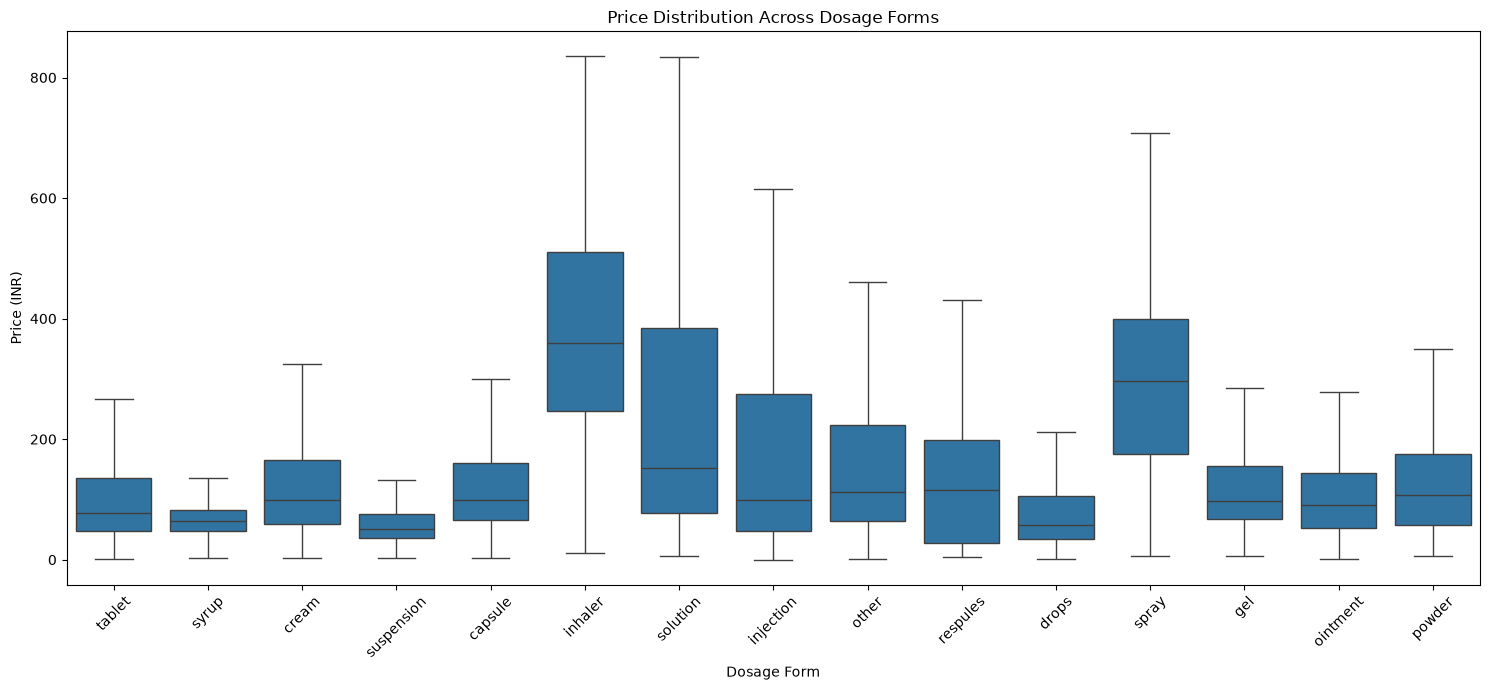

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x="dosage_form",
    y="price_inr",
    showfliers=False
)

plt.xticks(rotation=45)
plt.title("Price Distribution Across Dosage Forms")
plt.xlabel("Dosage Form")
plt.ylabel("Price (INR)")
plt.tight_layout()
plt.show()

### Key Observations

- Different dosage forms have different price distributions.
- Inhalers and sprays tend to have higher median prices than common tablets and syrups.
- Dosage form alone cannot explain medicine prices; strength, ingredients, manufacturer and pack size may also influence pricing.

### Manufacturer-wise pricing

In [25]:
manufacturer_price = df.groupby("manufacturer")["price_inr"].agg(
    ["count","mean","median"]
)

# Consider manufacturers with at least 30 products
reliable_manufacturers = manufacturer_price[
    manufacturer_price["count"]>=30
]

reliable_manufacturers = reliable_manufacturers.sort_values(
    by="median",
    ascending=False
)
reliable_manufacturers.head(20)

,count,mean,median
manufacturer,,,
Roche Products India Pvt Ltd,46,47397.537391,10287.500
Reliance Life Sciences,53,10459.180566,6000.000
Metta Life Sciences Private Limited,31,4676.322581,2700.000
Aureate Healthcare Pvt Ltd,50,5478.756400,2687.500
BDR Pharmaceuticals Internationals Pvt,58,8484.174138,2618.595
Tyykem Private Limited,37,3198.054054,1899.000
AMPS Biotech Pvt Ltd,31,3920.741935,1835.000
Shilpa Medicare Ltd,58,3742.477586,1327.500
Getwell Oncology Pvt Ltd,40,3632.125000,1304.500


In [26]:
top_manufacturers = df["manufacturer"].value_counts().head(20)
top_manufacturers

manufacturer
Sun Pharmaceutical Industries Ltd    2986
Cipla Ltd                            2467
Intas Pharmaceuticals Ltd            2302
Torrent Pharmaceuticals Ltd          2027
Alkem Laboratories Ltd               1809
Abbott                               1777
Zydus Cadila                         1768
Lupin Ltd                            1735
Micro Labs Ltd                       1305
Mankind Pharma Ltd                   1297
Macleods Pharmaceuticals Pvt Ltd     1165
Glenmark Pharmaceuticals Ltd         1131
Leeford Healthcare Ltd               1068
Dr Reddy's Laboratories Ltd           997
Cadila Pharmaceuticals Ltd            971
Emcure Pharmaceuticals Ltd            945
Alembic Pharmaceuticals Ltd           839
Ipca Laboratories Ltd                 806
Ajanta Pharma Ltd                     758
Wockhardt Ltd                         707
Name: count, dtype: int64

### Compare the largest manufacturers by price

In [27]:
top_20_names = df["manufacturer"].value_counts().head(20).index

top_20_manufacturer_analysis = (
    df[df["manufacturer"].isin(top_20_names)]
    .groupby("manufacturer")["price_inr"]
    .agg(["count","mean","median"])
    .sort_values(by="median",ascending=False)
)
top_20_manufacturer_analysis

,count,mean,median
manufacturer,,,
Emcure Pharmaceuticals Ltd,945,1691.678540,156.780
Dr Reddy's Laboratories Ltd,997,1492.279047,146.250
Ajanta Pharma Ltd,758,164.748047,135.500
Intas Pharmaceuticals Ltd,2302,866.344127,133.450
Lupin Ltd,1735,505.637914,130.530
Glenmark Pharmaceuticals Ltd,1131,741.282688,129.000
Macleods Pharmaceuticals Pvt Ltd,1165,209.057176,128.000
Sun Pharmaceutical Industries Ltd,2986,506.453449,123.000
Zydus Cadila,1768,938.165074,119.250


### Key Observations

- Medicine prices vary considerably across manufacturers.
- Manufacturers with higher median prices may have more expensive or specialised products.
- Large manufacturers by product count are not necessarily the manufacturers with the highest median prices.
- These comparisons are based on raw product prices and do not account for differences in strength, dosage form or pack size.

### Therapeutic-class-wise pricing

In [28]:
therapeutic_price = df.groupby("therapeutic_class")["price_inr"].agg(
    ["count","mean","median"]
    ).sort_values(by="median",ascending=False)
therapeutic_price

,count,mean,median
therapeutic_class,,,
other,144119,413.749735,95.000
diuretic,693,101.110909,81.200
antidiabetic,8957,92.677786,78.600
antibiotic,30660,99.639244,78.000
antihypertensive,7324,83.117041,73.325
bronchodilator,1802,67.923108,70.575
antacid,17432,81.536670,70.085
antidepressant,2499,73.629928,70.000
antihistamine,13414,71.298426,65.000


In [29]:
df["therapeutic_class"].value_counts()

therapeutic_class
other               144119
antibiotic           30660
analgesic            24105
antacid              17432
antihistamine        13414
antidiabetic          8957
antihypertensive      7324
corticosteroid        2968
antidepressant        2499
bronchodilator        1802
diuretic               693
Name: count, dtype: int64

### Analyse active ingredients

In [30]:
top_ingredients = df["primary_ingredient"].value_counts().head(20)
top_ingredients

primary_ingredient
Cefixime                8992
Domperidone             8869
Aceclofenac             8683
Amoxycillin             8550
Ofloxacin               6768
Ceftriaxone             6185
Cefpodoxime Proxetil    6098
Levocetirizine          5973
Glimepiride             5265
Azithromycin            4859
Diclofenac              4857
Telmisartan             4099
Nimesulide              3304
Cefuroxime              3267
Methylcobalamin         3183
Pantoprazole            2825
Itraconazole            2639
Rabeprazole             2513
Ondansetron             2500
Ambroxol                2384
Name: count, dtype: int64

In [31]:
top_ingredient_names = top_ingredients.index

ingredient_price = (
    df[df["primary_ingredient"].isin(top_ingredient_names)]
    .groupby("primary_ingredient")["price_inr"]
    .agg(["count", "mean", "median"])
    .sort_values(by="median", ascending=False)
)
ingredient_price

,count,mean,median
primary_ingredient,,,
Cefuroxime,3267,327.497885,289.00
Itraconazole,2639,163.265320,145.00
Cefpodoxime Proxetil,6098,151.785671,135.00
Cefixime,8992,124.339968,115.00
Amoxycillin,8550,110.300415,98.00
Methylcobalamin,3183,99.176296,90.00
Telmisartan,4099,95.515096,83.00
Domperidone,8869,78.790875,77.40
Glimepiride,5265,85.450522,73.00


### Compare price distributions across ingredients

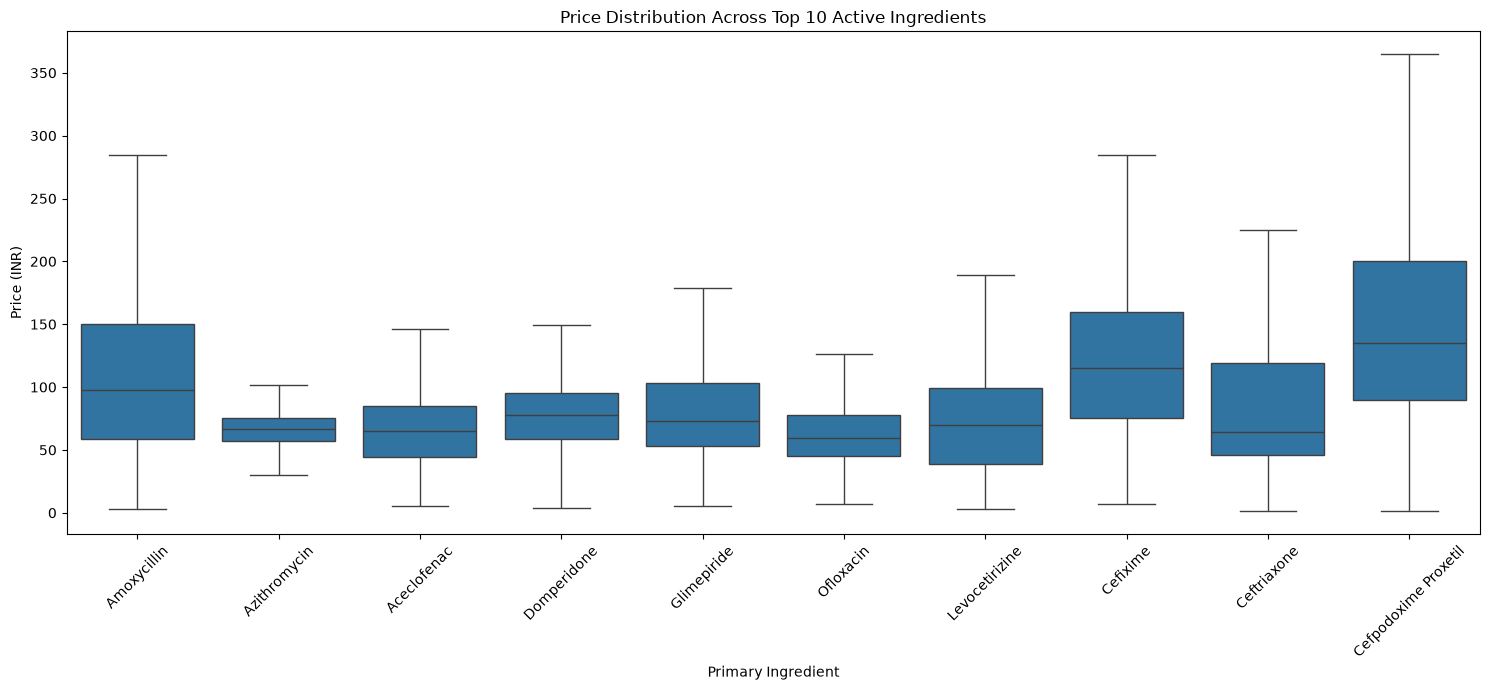

In [32]:
top_10_ingredients = (
    df["primary_ingredient"]
    .value_counts()
    .head(10)
    .index
)

ingredient_df = df[
    df["primary_ingredient"].isin(top_10_ingredients)
]
plt.figure(figsize=(15, 7))

sns.boxplot(
    data=ingredient_df,
    x="primary_ingredient",
    y="price_inr",
    showfliers=False
)

plt.xticks(rotation=45)
plt.title("Price Distribution Across Top 10 Active Ingredients")
plt.xlabel("Primary Ingredient")
plt.ylabel("Price (INR)")
plt.tight_layout()
plt.show()

Our EDA conclusion
We can record these findings:
1. Price variation exists even among products sharing the same primary ingredient.
2. Cefpodoxime Proxetil and Cefixime show relatively high median prices among these 10 ingredients.
3. Azithromycin and Ofloxacin have comparatively compact price distributions.
4. Ingredient alone is unlikely to explain pharmaceutical product pricing.

### Analyze discontinued vs active medicines

In [33]:
discontinued_price = df.groupby("is_discontinued")["price_inr"].agg(
    ["count", "mean", "median", "min", "max"]
)

discontinued_price

,count,mean,median,min,max
is_discontinued,,,,,
False,246068,265.002121,79.0,0.00,436000.0
True,7905,442.629725,77.0,1.25,110700.0


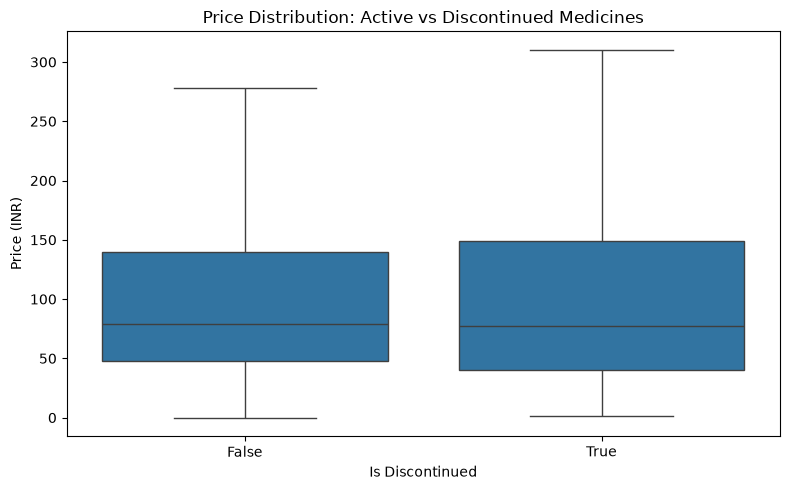

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="is_discontinued",
    y="price_inr",
    showfliers=False
)

plt.title("Price Distribution: Active vs Discontinued Medicines")
plt.xlabel("Is Discontinued")
plt.ylabel("Price (INR)")

plt.tight_layout()
plt.show()

Our current findings:
1. Discontinued products represent only around 3.11% of the dataset.
2. Their mean price is higher than that of active products.
3. Their median price is slightly lower.
4. We cannot conclude that discontinued status causes a price difference.

### Number of active ingredients vs price

In [35]:
ingredient_count_price = df.groupby("num_active_ingredients")["price_inr"].agg(
    ["count","mean","median"]
    ).sort_values(by="median",ascending=False)

ingredient_count_price

,count,mean,median
num_active_ingredients,,,
4,1,5440.000000,5440.0
5,2,3927.000000,3927.0
3,8,1143.081250,850.0
2,112202,127.463398,85.0
1,141760,383.630384,72.5


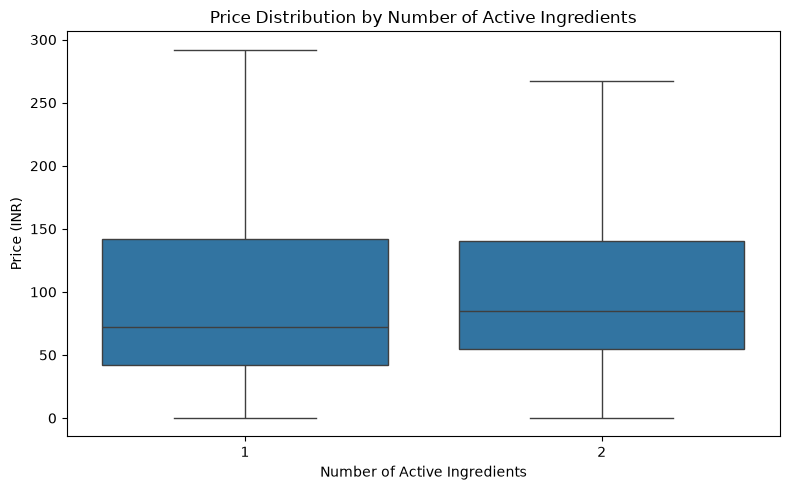

In [36]:
ingredient_count_df = df[
    df["num_active_ingredients"].isin([1, 2])
]

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=ingredient_count_df,
    x="num_active_ingredients",
    y="price_inr",
    showfliers=False
)

plt.title("Price Distribution by Number of Active Ingredients")
plt.xlabel("Number of Active Ingredients")
plt.ylabel("Price (INR)")

plt.tight_layout()
plt.show()

Products containing two active ingredients have a slightly higher median price than single-ingredient products. However, the distributions overlap substantially, suggesting that other factors, such as strength, dosage form, manufacturer and packaging, also contribute to price variation.

### Analyze pack size

In [37]:
print(df["pack_size"].describe())
print("Missing values:", df["pack_size"].isnull().sum())
print("Unique pack sizes:", df["pack_size"].nunique())

count    231643.000000
mean         18.988871
std          36.717320
min           1.000000
25%          10.000000
50%          10.000000
75%          10.000000
max        5000.000000
Name: pack_size, dtype: float64
Missing values: 22330
Unique pack sizes: 91


In [38]:
pack_size_counts = df["pack_size"].value_counts().head(15)

print(pack_size_counts)

pack_size
10.0     155077
30.0      12281
15.0       9525
100.0      8334
60.0       7719
5.0        6463
6.0        6273
1.0        5231
2.0        5075
4.0        3431
3.0        2568
20.0       2067
200.0      1868
50.0        902
170.0       821
Name: count, dtype: int64


In [39]:
print(df["pack_unit"].value_counts(dropna=False))

pack_unit
strip     172122
bottle     33772
NaN        22330
ml         14790
tube        8241
units       1424
gm          1294
Name: count, dtype: int64


### Analyze price by packaging unit

In [40]:
pack_unit_price = df.groupby("pack_unit",dropna=False)["price_inr"].agg(
    ["count", "mean", "median", "min", "max"]
).sort_values(by="median", ascending=False)

pack_unit_price

,count,mean,median,min,max
pack_unit,,,,,
units,1424,5304.603315,260.625,2.50,436000.00
NaN,22330,849.962185,130.000,1.25,330000.00
gm,1294,165.298168,108.000,5.00,7816.53
tube,8241,131.691251,96.180,1.25,7000.00
strip,172122,139.197537,80.000,1.05,204435.84
ml,14790,815.100477,67.080,0.00,396725.00
bottle,33772,143.925778,65.000,1.25,156451.30


### Strength Analysis

In [41]:
print("Missing strengths:", df["primary_strength"].isnull().sum())
print("Unique strengths:", df["primary_strength"].nunique())

Missing strengths: 25198
Unique strengths: 673


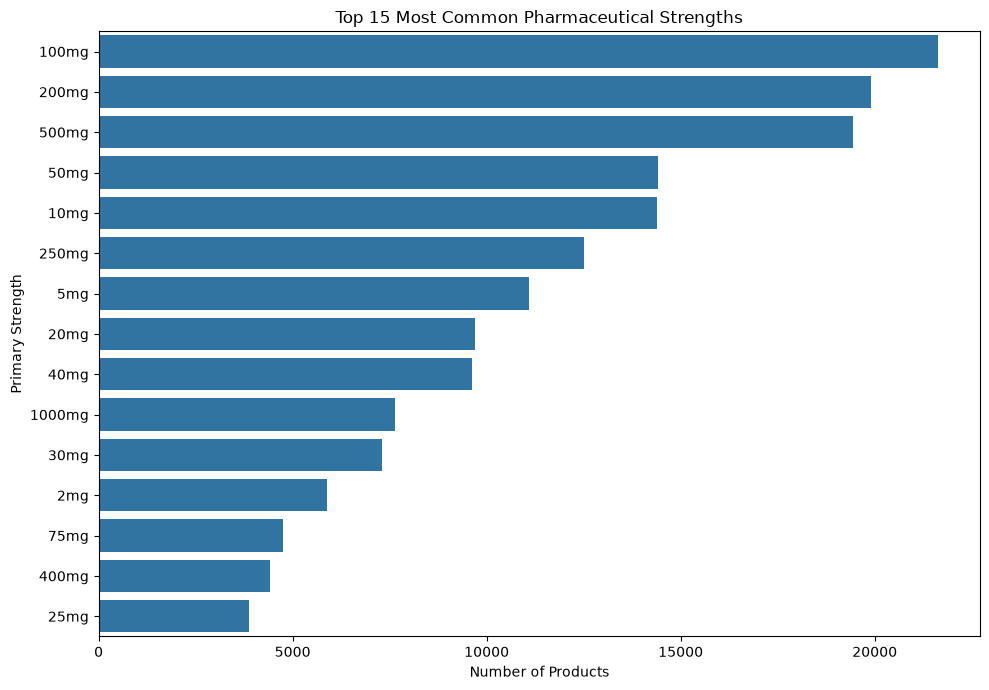

In [42]:
strength_counts = df["primary_strength"].value_counts().head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=strength_counts.values,
    y=strength_counts.index
)

plt.title("Top 15 Most Common Pharmaceutical Strengths")
plt.xlabel("Number of Products")
plt.ylabel("Primary Strength")

plt.tight_layout()
plt.show()

### Analyze Price against Primary strength

In [43]:
top_strengths = df["primary_strength"].value_counts().head(15).index

strength_price = df[
    df["primary_strength"].isin(top_strengths)
].groupby("primary_strength")["price_inr"].agg(
       ["count", "mean", "median", "min", "max"]
).sort_values(by="median", ascending=False)
strength_price

,count,mean,median,min,max
primary_strength,,,,,
75mg,4752,154.741088,147.000,2.05,95000.00
1000mg,7641,397.447352,138.100,2.87,168520.00
200mg,19898,188.975907,127.000,1.25,146037.50
500mg,19437,303.986316,96.000,1.25,257532.00
30mg,7312,148.677254,87.000,2.46,75447.50
400mg,4410,550.404776,85.000,2.06,117625.00
40mg,9628,248.868059,75.000,1.40,335635.00
100mg,21632,268.360070,73.000,1.68,312000.00
20mg,9695,196.094761,69.000,1.90,82820.00


Price distributions vary across primary strength categories. However, there is no consistent relationship between numerical strength and median price. Differences in active ingredients, dosage forms, manufacturers and packaging may contribute to these variations.

### Correlation Analysis

In [44]:
numerical_df = df.select_dtypes(include=["int64","float64"])
correlation = numerical_df.corr()
correlation

,product_id,price_inr,pack_size,num_active_ingredients
product_id,1.000000,-0.000851,-0.016448,0.003073
price_inr,-0.000851,1.000000,0.016590,-0.041841
pack_size,-0.016448,0.016590,1.000000,0.100636
num_active_ingredients,0.003073,-0.041841,0.100636,1.000000


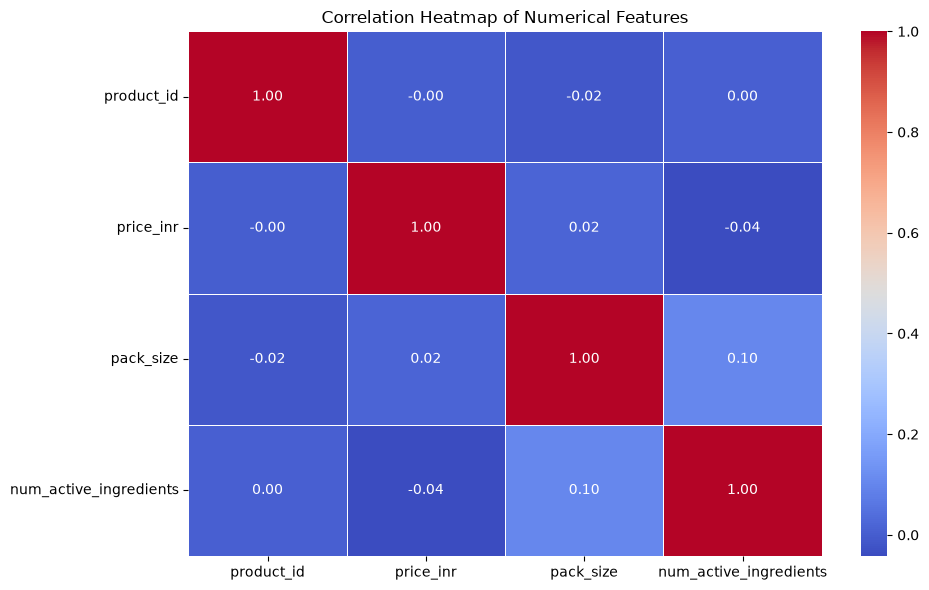

In [45]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

#### Spearman correlation

Pearson measures linear relationships, whereas Spearman measures monotonic relationships using ranks. This can be useful when relationships are not linear.

In [46]:
spearman_corr = numerical_df.corr(method="spearman")
spearman_corr

,product_id,price_inr,pack_size,num_active_ingredients
product_id,1.000000,0.018161,0.000416,0.003079
price_inr,0.018161,1.000000,0.003730,0.073757
pack_size,0.000416,0.003730,1.000000,0.174146
num_active_ingredients,0.003079,0.073757,0.174146,1.000000


### Categorical Feature Cardinality

In [47]:
categorical_df = df.select_dtypes(include=["object","bool"])
cardinality = pd.DataFrame({
    "Unique_Values": categorical_df.nunique(),
    "Missing_Values": categorical_df.isnull().sum()
})
cardinality = cardinality.sort_values(
    by="Unique_Values",
    ascending=False
)
cardinality

,Unique_Values,Missing_Values
brand_name,249398,0
active_ingredients,11802,0
manufacturer,7648,0
manufacturer_raw,7648,0
packaging_raw,1929,0
primary_ingredient,1586,0
primary_strength,673,25198
dosage_form,15,0
therapeutic_class,11,0
pack_unit,6,22330


In [48]:
# import re

# def normalize_text(value):
#     return re.sub(r"\s+", " ", str(value)).strip().lower()

# comparison = (
#     df["manufacturer_raw"].apply(normalize_text)
#     ==
#     df["manufacturer"].apply(normalize_text)
# )

# print("Matching after normalization:", comparison.sum())
# print("Still different:", (~comparison).sum())

In [49]:
# different_after_normalization = df.loc[
#     ~comparison,
#     ["manufacturer_raw", "manufacturer"]
# ]

# print("Remaining different records:", len(different_after_normalization))

# print(different_after_normalization.head(30))

In [50]:
# different_after_normalization.value_counts().head(20)

### Manufacturer Feature Engineering

In [51]:
df["manufacturer_clean"] = (
    df["manufacturer_raw"]
    .str.strip()
    .str.replace(r"\s+"," ",regex=True)
    .str.title()
)

In [52]:
df[[
    "manufacturer_raw",
    "manufacturer",
    "manufacturer_clean"
]].head(20)

,manufacturer_raw,manufacturer,manufacturer_clean
0,Glaxo SmithKline Pharmaceuticals Ltd,Glaxo SmithKline Pharmaceuticals Ltd,Glaxo Smithkline Pharmaceuticals Ltd
1,Alembic Pharmaceuticals Ltd,Alembic Pharmaceuticals Ltd,Alembic Pharmaceuticals Ltd
2,Glenmark Pharmaceuticals Ltd,Glenmark Pharmaceuticals Ltd,Glenmark Pharmaceuticals Ltd
3,Sanofi India Ltd,Sanofi India Ltd,Sanofi India Ltd
4,Sanofi India Ltd,Sanofi India Ltd,Sanofi India Ltd
5,Sanofi India Ltd,Sanofi India Ltd,Sanofi India Ltd
6,Abbott,Abbott,Abbott
7,Cipla Ltd,Cipla Ltd,Cipla Ltd
8,Dr Reddy's Laboratories Ltd,Dr Reddy's Laboratories Ltd,Dr Reddy'S Laboratories Ltd
9,Glenmark Pharmaceuticals Ltd,Glenmark Pharmaceuticals Ltd,Glenmark Pharmaceuticals Ltd


In [53]:
df.drop(
    columns=["manufacturer", "manufacturer_raw"],
    inplace=True
)

In [54]:
df.head(5)

,product_id,brand_name,price_inr,is_discontinued,dosage_form,pack_size,pack_unit,num_active_ingredients,primary_ingredient,primary_strength,active_ingredients,therapeutic_class,packaging_raw,manufacturer_clean
0,1,Augmentin 625 Duo Tablet,223.42,False,tablet,10.0,strip,2,Amoxycillin,500mg,"[{'name': 'Amoxycillin', 'strength': '500mg', ...",antibiotic,strip of 10 tablets,Glaxo Smithkline Pharmaceuticals Ltd
1,2,Azithral 500 Tablet,132.36,False,tablet,5.0,strip,1,Azithromycin,500mg,"[{'name': 'Azithromycin', 'strength': '500mg',...",antibiotic,strip of 5 tablets,Alembic Pharmaceuticals Ltd
2,3,Ascoril LS Syrup,118.00,False,syrup,100.0,bottle,2,Ambroxol,30mg/5ml,"[{'name': 'Ambroxol', 'strength': '30mg/5ml', ...",bronchodilator,bottle of 100 ml Syrup,Glenmark Pharmaceuticals Ltd
3,4,Allegra 120mg Tablet,218.81,False,tablet,10.0,strip,1,Fexofenadine,120mg,"[{'name': 'Fexofenadine', 'strength': '120mg',...",antihistamine,strip of 10 tablets,Sanofi India Ltd
4,5,Avil 25 Tablet,10.96,False,tablet,15.0,strip,1,Pheniramine,25mg,"[{'name': 'Pheniramine', 'strength': '25mg', '...",other,strip of 15 tablets,Sanofi India Ltd


### Active Ingredient 

In [55]:
print("ACTIVE INGREDIENTS:")
print(df["active_ingredients"].head(15))

print("\nPACKAGING RAW:")
print(df["packaging_raw"].head(15))



ACTIVE INGREDIENTS:
0     [{'name': 'Amoxycillin', 'strength': '500mg', ...
1     [{'name': 'Azithromycin', 'strength': '500mg',...
2     [{'name': 'Ambroxol', 'strength': '30mg/5ml', ...
3     [{'name': 'Fexofenadine', 'strength': '120mg',...
4     [{'name': 'Pheniramine', 'strength': '25mg', '...
5     [{'name': 'Montelukast', 'strength': '10mg', '...
6     [{'name': 'Amoxycillin', 'strength': '500mg', ...
7     [{'name': 'Azithromycin', 'strength': '500mg',...
8     [{'name': 'Hydroxyzine', 'strength': '25mg', '...
9     [{'name': 'Phenylephrine', 'strength': '5mg', ...
10    [{'name': 'Ranitidine', 'strength': '150mg', '...
11    [{'name': 'Phenylephrine', 'strength': '5mg/5m...
12    [{'name': 'Phenylephrine', 'strength': None, '...
13    [{'name': 'Amoxycillin', 'strength': '200mg', ...
14    [{'name': 'Ambroxol', 'strength': '15mg/5ml', ...
Name: active_ingredients, dtype: str

PACKAGING RAW:
0                 strip of 10 tablets
1                  strip of 5 tablets
2          

In [56]:
import ast
import pandas as pd

def parse_ingredients(value):
    try:
        if pd.isna(value):
            return []

        return ast.literal_eval(value)

    except (ValueError, SyntaxError, TypeError):
        return []

In [57]:
df["ingredient_names"] = df["active_ingredients"].apply(
    lambda x: [item["name"] for item in parse_ingredients(x)]
)

In [58]:
df["ingredient_strengths"] = df["active_ingredients"].apply(
    lambda x: [item["strength"] for item in parse_ingredients(x)]
)

In [59]:
print(df[[
    "active_ingredients",
    "ingredient_names",
    "ingredient_strengths"
]].head(10).to_string(index=False))

                                                                                                                                                                                      active_ingredients                          ingredient_names ingredient_strengths
             [{'name': 'Amoxycillin', 'strength': '500mg', 'full_description': 'Amoxycillin  (500mg)'}, {'name': 'Clavulanic Acid', 'strength': '125mg', 'full_description': 'Clavulanic Acid (125mg)'}]            [Amoxycillin, Clavulanic Acid]       g, 125mg]
                                                                                                             [{'name': 'Azithromycin', 'strength': '500mg', 'full_description': 'Azithromycin (500mg)'}]                            [Azithromycin]              g]
            [{'name': 'Ambroxol', 'strength': '30mg/5ml', 'full_description': 'Ambroxol (30mg/5ml)'}, {'name': 'Levosalbutamol', 'strength': '1mg/5ml', 'full_description': 'Levosalbutamol (1mg/5ml)'}]                [A

### Next step: Validate the extraction
Let's check whether any records failed parsing or have empty extracted ingredient names.

In [60]:
print("Total records:", len(df))

print(
    "Records with no extracted ingredients:",
    (df["ingredient_names"].str.len() == 0).sum()
)

print(
    "Records with multiple ingredients:",
    (df["ingredient_names"].str.len() > 1).sum()
)

print(
    "Maximum ingredients in one medicine:",
    df["ingredient_names"].str.len().max()
)

Total records: 253973
Records with no extracted ingredients: 0
Records with multiple ingredients: 112213
Maximum ingredients in one medicine: 5


In [61]:
df["extracted_ingredient_count"] = (
    df["ingredient_names"].str.len()
)

print(
    "Matching records:",
    (
        df["extracted_ingredient_count"]
        == df["num_active_ingredients"]
    ).sum()
)

print(
    "Mismatching records:",
    (
        df["extracted_ingredient_count"]
        != df["num_active_ingredients"]
    ).sum()
)

Matching records: 253973
Mismatching records: 0


#### All 253,973 records match exactly. This confirms that:
- ingredient_names was extracted correctly.
- num_active_ingredients already contains the same information.
- There are no inconsistencies between the two columns.

### Analyse Active Ingredient Combinations

In [196]:
# Create a normalized ingredient combination for analysis

df["ingredient_combination"] = df["ingredient_names"].apply(
    lambda ingredients: " + ".join(
        sorted({
            str(name).strip().casefold()
            for name in ingredients
            if pd.notna(name) and str(name).strip()
        })
    )
)

# Count unique ingredient combinations

print(
    "Unique ingredient combinations:",
    df["ingredient_combination"].nunique()
)

# Identify the most common combinations

combination_summary = (
    df.groupby("ingredient_combination")["price_inr"]
    .agg(
        product_count="count",
        median_price="median",
        mean_price="mean"
    )
    .sort_values("product_count", ascending=False)
)

combination_summary.head(20)

Unique ingredient combinations: 2984


,product_count,median_price,mean_price
ingredient_combination,,,
aceclofenac + paracetamol,6491,60.000,62.318623
amoxycillin + clavulanic acid,5883,125.000,134.576028
azithromycin,4720,66.000,74.938498
cefixime,4608,85.000,90.410948
glimepiride + metformin,4408,79.600,91.444201
cefpodoxime proxetil,4336,119.700,130.435657
levocetirizine + montelukast,3631,95.000,95.676153
domperidone + rabeprazole,3329,84.000,85.690811
ofloxacin,3214,51.905,55.332971


### Let's inspect packaging information(Packaging Feature Engineering)

In [62]:
print(df["packaging_raw"].value_counts().head(20))

packaging_raw
strip of 10 tablets                116540
vial of 1 Injection                 17678
strip of 10 capsules                11931
strip of 6 tablets                   5718
bottle of 100 ml Syrup               5663
strip of 10 capsule sr               5511
strip of 10 tablet sr                5116
strip of 10 tablet dt                4309
vial of 2 ml Injection               3994
bottle of 30 ml Dry Syrup            3709
bottle of 60 ml Syrup                3330
strip of 15 tablets                  3260
vial of 1 ml Injection               2540
bottle of 60 ml Oral Suspension      2511
bottle of 30 ml Oral Suspension      2206
bottle of 30 ml Syrup                1896
strip of 10 tablet er                1871
strip of 3 tablets                   1796
strip of 10 tablet md                1778
tube of 15 gm Cream                  1763
Name: count, dtype: int64


In [63]:
print(df[[
    "packaging_raw",
    "pack_size",
    "pack_unit",
    "dosage_form"
]].head(30).to_string(index=False))

                  packaging_raw  pack_size pack_unit dosage_form
            strip of 10 tablets       10.0     strip      tablet
             strip of 5 tablets        5.0     strip      tablet
         bottle of 100 ml Syrup      100.0    bottle       syrup
            strip of 10 tablets       10.0     strip      tablet
            strip of 15 tablets       15.0     strip      tablet
            strip of 10 tablets       10.0     strip      tablet
            strip of 10 tablets       10.0     strip      tablet
             strip of 5 tablets        5.0     strip      tablet
            strip of 15 tablets       15.0     strip      tablet
         bottle of 100 ml Syrup      100.0    bottle       syrup
            strip of 30 tablets       30.0     strip      tablet
         bottle of 100 ml Syrup      100.0    bottle       syrup
            tube of 20 gm Cream       20.0      tube       cream
bottle of 30 ml Oral Suspension       30.0    bottle  suspension
         bottle of 100 ml

##### packet of 200 MDI Inhaler
##### pack_size = NaN
##### pack_unit = NaN
##### dosage_form = inhaler

#### This means packaging_raw may contain useful information that is missing from the structured columns.

#### Extract package type

In [64]:
df["package_type"] = (
    df["packaging_raw"]
    .str.extract(r"^(\w+)", expand=False)
    .str.lower()
)

In [65]:
print(df["package_type"].value_counts(dropna=False))

package_type
strip         173397
bottle         35439
vial           29246
tube            8328
packet          3913
ampoule         1761
box             1124
prefilled        389
sachet           152
pump              61
cartridge         52
jar               36
pre               34
penfill           17
flexpen            7
disposable         7
pouch              3
roll               2
combo              2
canister           1
tin                1
kit                1
Name: count, dtype: int64


We'll then investigate whether this feature adds useful information beyond pack_unit, especially for records where pack_unit is missing.

#### Compare package_type with pack_unit

In [66]:
print(pd.crosstab(
    df["package_type"],
    df["pack_unit"],
    margins=True
))

pack_unit     bottle    gm     ml   strip  tube  units     All
package_type                                                  
ampoule            0     0   1630       0     0      0    1630
bottle         33743   256     45       0     0   1218   35262
box                0   381     40       0     0     74     495
cartridge          0     0     47       0     0      0      47
disposable         0     0      6       0     0      0       6
flexpen            0     0      7       0     0      0       7
jar                0    30      0       0     0      4      34
packet             0   413   2419       0     0    128    2960
penfill            0     0     15       0     0      0      15
pre                0     0     29       0     0      0      29
prefilled          0     0    316       0     0      0     316
pump              28    16      1       0     0      0      45
roll               1     1      0       0     0      0       2
sachet             0   143      2       0     0      0 

#### Extract package quantity

In [67]:
df["package_quantity"] = pd.to_numeric(
    df["packaging_raw"].str.extract(
        r"\bof\s+([\d,.]+)",
        expand=False
    ).str.replace(",", ""),
    errors="coerce"
)

In [68]:
print("Total records:", len(df))

print(
    "Missing package quantity:",
    df["package_quantity"].isna().sum()
)

print(
    "Successfully extracted:",
    df["package_quantity"].notna().sum()
)

Total records: 253973
Missing package quantity: 0
Successfully extracted: 253973


### Compare package_quantity with pack_size

In [69]:
comparison = df[
    ["package_quantity", "pack_size"]
].copy()

print("Exact matches:")
print(
    (
        comparison["package_quantity"]
        == comparison["pack_size"]
    ).sum()
)

print("\nMismatches:")
print(
    (
        comparison["package_quantity"]
        != comparison["pack_size"]
    ).sum()
)

print("\nExamples of mismatches:")
print(
    df.loc[
        df["package_quantity"] != df["pack_size"],
        ["packaging_raw", "package_quantity", "pack_size", "pack_unit"]
    ].head(20).to_string(index=False)
)

Exact matches:
230893

Mismatches:
23080

Examples of mismatches:
                    packaging_raw  package_quantity  pack_size pack_unit
        packet of 200 MDI Inhaler             200.0        NaN       NaN
           packet of 6 injections               6.0        NaN       NaN
             strip of 10 lozenges              10.0        NaN       NaN
        packet of 2.5 ml Respules               2.5        5.0        ml
                  packet of 1 Kit               1.0        NaN       NaN
        packet of 200 MDI Inhaler             200.0        NaN       NaN
              vial of 1 Injection               1.0        NaN       NaN
   vial of 1 Powder for Injection               1.0        NaN       NaN
    bottle of 120 MDI Nasal Spray             120.0        NaN       NaN
              vial of 1 Injection               1.0        NaN       NaN
                  packet of 1 Kit               1.0        NaN       NaN
               vial of 1 Infusion               1.0       

In [70]:
mismatch_df = df[
    df["package_quantity"] != df["pack_size"]
]
print(
    "Pack size missing:",
    mismatch_df["pack_size"].isna().sum()
)

print(
    "Pack size available:",
    mismatch_df["pack_size"].notna().sum()
)

Pack size missing: 22330
Pack size available: 750


#### Inspect the 750 disagreements

In [71]:
different_pack_sizes = df[
    df["pack_size"].notna()
    & (df["package_quantity"] != df["pack_size"])
]
print(
    different_pack_sizes[
        ["packaging_raw", "package_quantity", "pack_size", "pack_unit"]
    ].head(30).to_string(index=False)
)


                          packaging_raw  package_quantity  pack_size pack_unit
              packet of 2.5 ml Respules             2.500        5.0        ml
          bottle of 2.5 ml Nail Lacquer             2.500        5.0        ml
              sachet of 3.2 gm Granules             3.200        2.0        gm
                  packet of 7.5 ml Drop             7.500        5.0        ml
 prefilled syringe of 0.42 ml Injection             0.420       42.0        ml
       bottle of 7.5 ml Oral Suspension             7.500        5.0        ml
               vial of 0.5 ml Injection             0.500        5.0        ml
              vial of 12.5 ml Injection            12.500        5.0        ml
  prefilled syringe of 0.3 ml Injection             0.300        3.0        ml
               strip of 2.5 ml Respules             2.500        5.0        ml
          bottle of 2.5 ml Nail Lacquer             2.500        5.0        ml
              packet of 2.5 ml Eye Drop             

Let's check whether all 750 disagreements follow this decimal-conversion pattern.

In [72]:
different_pack_sizes["ratio"] = (
    different_pack_sizes["pack_size"]
    / different_pack_sizes["package_quantity"]
)
different_pack_sizes["ratio"].value_counts().head(20)

ratio
10.000000     445
2.000000      139
3.333333       25
0.666667       22
100.000000     22
0.419162       15
1.891892       11
0.092166       10
1.666667        9
0.816327        6
0.625000        3
0.476190        3
111.111111      3
1.428571        3
1.304348        3
1.111111        3
0.400000        2
1.525424        2
20.000000       2
0.384615        2
Name: count, dtype: int64

#### Inspect the most common ratio (10)

In [73]:
ratio_10 = different_pack_sizes[
    different_pack_sizes["ratio"] == 10
]

print("Records with ratio 10:", len(ratio_10))

print(
    ratio_10[
        [
            "packaging_raw",
            "package_quantity",
            "pack_size",
            "pack_unit",
            "dosage_form"
        ]
    ].head(30).to_string(index=False)
)


Records with ratio 10: 445
                        packaging_raw  package_quantity  pack_size pack_unit dosage_form
             vial of 0.5 ml Injection               0.5        5.0        ml   injection
prefilled syringe of 0.3 ml Injection               0.3        3.0        ml   injection
             vial of 0.8 ml Injection               0.8        8.0        ml   injection
             vial of 0.5 ml Injection               0.5        5.0        ml   injection
prefilled syringe of 0.5 ml Injection               0.5        5.0        ml   injection
prefilled syringe of 0.4 ml Injection               0.4        4.0        ml   injection
             vial of 0.5 ml Injection               0.5        5.0        ml   injection
prefilled syringe of 0.5 ml Injection               0.5        5.0        ml   injection
             vial of 0.6 ml Injection               0.6        6.0        ml   injection
prefilled syringe of 0.8 ml Injection               0.8        8.0        ml   inje

#### Check whether all 445 follow the decimal pattern

In [74]:
ratio_10["expected_pack_size"] = (
    ratio_10["package_quantity"] * 10
)

print(
    (
        ratio_10["pack_size"]
        == ratio_10["expected_pack_size"]
    ).all()
)

True


#### proposed data-cleaning strategy

In [75]:
df["pack_size_final"] = df["pack_size"]

# Fill missing pack sizes
df["pack_size_final"] = df["pack_size_final"].fillna(
    df["package_quantity"]
)

# Correct verified decimal-conversion errors
df.loc[
    ratio_10.index,
    "pack_size_final"
] = ratio_10["package_quantity"]

In [76]:
print("Original missing:", df["pack_size"].isna().sum())

print("Final missing:", df["pack_size_final"].isna().sum())

print(
    df.loc[
        ratio_10.index,
        ["packaging_raw", "pack_size", "pack_size_final"]
    ].head(10)
)

Original missing: 22330
Final missing: 0
                              packaging_raw  pack_size  pack_size_final
1209               vial of 0.5 ml Injection        5.0              0.5
1325  prefilled syringe of 0.3 ml Injection        3.0              0.3
1844               vial of 0.8 ml Injection        8.0              0.8
2011               vial of 0.5 ml Injection        5.0              0.5
2401  prefilled syringe of 0.5 ml Injection        5.0              0.5
2410  prefilled syringe of 0.4 ml Injection        4.0              0.4
2462               vial of 0.5 ml Injection        5.0              0.5
2856  prefilled syringe of 0.5 ml Injection        5.0              0.5
3344               vial of 0.6 ml Injection        6.0              0.6
4181  prefilled syringe of 0.8 ml Injection        8.0              0.8


#### Next: Investigate the remaining 305 mismatches

In [77]:
remaining_mismatches = df[
    df["pack_size"].notna() &
    (df["pack_size"] != df["package_quantity"]) &
    (~df.index.isin(ratio_10.index))
]
print("Remaining mismatches:", len(remaining_mismatches))

remaining_mismatches[
    ["packaging_raw", "pack_size", "package_quantity", "pack_unit", "dosage_form"]
].head(30)

Remaining mismatches: 305


,packaging_raw,pack_size,package_quantity,pack_unit,dosage_form
54,packet of 2.5 ml Respules,5.0,2.500,ml,respules
373,bottle of 2.5 ml Nail Lacquer,5.0,2.500,ml,other
570,sachet of 3.2 gm Granules,2.0,3.200,gm,other
642,packet of 7.5 ml Drop,5.0,7.500,ml,drops
1137,prefilled syringe of 0.42 ml Injection,42.0,0.420,ml,injection
1207,bottle of 7.5 ml Oral Suspension,5.0,7.500,ml,suspension
1317,vial of 12.5 ml Injection,5.0,12.500,ml,injection
1331,strip of 2.5 ml Respules,5.0,2.500,ml,respules
1521,bottle of 2.5 ml Nail Lacquer,5.0,2.500,ml,other
1813,packet of 2.5 ml Eye Drop,5.0,2.500,ml,drops


In [78]:
#Create a mismatch flag
df["pack_size_mismatch"] = (
    df["pack_size"].notna() &
    (df["pack_size"] != df["package_quantity"]) &
    (~df.index.isin(ratio_10.index))
)

print(df["pack_size_mismatch"].value_counts())

pack_size_mismatch
False    253668
True        305
Name: count, dtype: int64


In [79]:
print(df["pack_size_final"].describe())

print("\nMissing values:")
print(df["pack_size_final"].isna().sum())

print("\nNumber of unresolved mismatches:")
print(df["pack_size_mismatch"].sum())

count    253973.000000
mean         17.640575
std          35.813711
min           0.100000
25%          10.000000
50%          10.000000
75%          10.000000
max        5000.000000
Name: pack_size_final, dtype: float64

Missing values:
0

Number of unresolved mismatches:
305


#### Next step: Investigate primary_strength

In [80]:
print("Unique strengths:", df["primary_strength"].nunique())
print("\nMissing values:", df["primary_strength"].isna().sum())

print("\nMost common strengths:")
print(df["primary_strength"].value_counts().head(30))

print("\nSample strength values:")
print(df["primary_strength"].sample(20, random_state=42).tolist())

Unique strengths: 673

Missing values: 25198

Most common strengths:
primary_strength
100mg       21632
200mg       19898
500mg       19437
50mg        14421
10mg        14402
250mg       12509
5mg         11082
20mg         9695
40mg         9628
1000mg       7641
30mg         7312
2mg          5876
75mg         4752
400mg        4410
25mg         3886
1mg          3845
4mg          3531
150mg        3418
80mg         3043
300mg        2766
2.5mg        2594
0.5mg        2306
6mg          2125
60mg         2118
125mg        1845
50mg/5ml     1781
8mg          1566
15mg         1380
90mg         1353
0.25mg       1188
Name: count, dtype: int64

Sample strength values:
['138mg/5ml', '50mg', '20mg', '50mg/5ml', '200mg', '1000mg', '50mg', '400mg/5ml', '160mg', '200mg', '500mg', '400mg', '0.25mg', '50mg', '50mg', '10mg', '400mg', '30mg', '400mg', '200mg']


#### identify all strength units and formats

In [81]:
# Count the different units appearing in primary_strength

strength_units = (
    df["primary_strength"]
    .str.extractall(r"([a-zA-Zµ%]+)")
    [0]
    .str.lower()
    .value_counts()
)

print(strength_units)

0
mg    226237
ml     11261
gm      1697
%        752
g          3
k          2
Name: count, dtype: int64


In [82]:
print(
    df["primary_strength"]
    .dropna()
    .sample(50, random_state=42)
    .tolist()
)

['40mg', '2mg', '400mg', '30mg', '50mg', '75mg', '10mg', '1000mg', '200mg', '100mg', '5mg', '100mg', '5mg', '250mg', '2mg', '400mg', '100mg', '50mg', '500mg', '10mg', '100mg', '500mg', '120mg', '40mg', '200mg', '100mg', '200mg', '100mg', '2mg', '10mg', '500mg', '5mg', '200mg', '400mg', '20mg', '10mg', '50mg', '2.5mg', '0.5mg', '35mg', '1000mg', '250mg', '500mg', '50mg', '8mg', '300mg', '75mg', '100mg', '250mg', '10mg']


Don't modify or drop primary_strength yet. We'll preserve the original column and build structured features alongside it. Share both outputs, and we'll design the parsing logic based on the real data.

In [83]:
# Values containing ml
print("Values containing ml:")
print(
    df.loc[
        df["primary_strength"].str.contains("ml", na=False),
        "primary_strength"
    ].value_counts().head(20)
)

# Values containing gm or g
print("\nValues containing gm or g:")
print(
    df.loc[
        df["primary_strength"].str.contains(r"gm|g", case=False, na=False),
        "primary_strength"
    ].value_counts().head(20)
)

# Values containing %
print("\nPercentage values:")
print(
    df.loc[
        df["primary_strength"].str.contains("%", na=False),
        "primary_strength"
    ].value_counts().head(20)
)

# Values containing k
print("\nValues containing k:")
print(
    df.loc[
        df["primary_strength"].str.contains("k", case=False, na=False),
        "primary_strength"
    ].value_counts()
)

Values containing ml:
primary_strength
50mg/5ml     1781
2mg/5ml      1061
5mg/5ml       988
15mg/5ml      919
100mg/5ml     871
200mg/5ml     673
2.5mg/5ml     508
30mg/5ml      485
1mg/5ml       429
125mg/5ml     311
400mg/5ml     292
250mg/5ml     266
4mg/5ml       219
10mg/5ml      192
2mg/ml        154
500mg/5ml     138
1mg/ml        108
100mg/ml       90
6mg/5ml        86
0.5mg/5ml      77
Name: count, dtype: int64

Values containing gm or g:
primary_strength
100mg     21632
200mg     19898
500mg     19437
50mg      14421
10mg      14402
250mg     12509
5mg       11082
20mg       9695
40mg       9628
1000mg     7641
30mg       7312
2mg        5876
75mg       4752
400mg      4410
25mg       3886
1mg        3845
4mg        3531
150mg      3418
80mg       3043
300mg      2766
Name: count, dtype: int64

Percentage values:
primary_strength
1%        119
2%         99
5%         72
0.1%       68
0.5%       61
0.3%       37
20%        36
70%        31
50%        26
10%        21
0.025% 

In [84]:
# Match standalone gm or g units
gram_values = df.loc[
    df["primary_strength"].str.contains(
        r"\d+(?:\.\d+)?\s*(?:gm|g)(?:/|$)",
        case=False,
        na=False
    ),
    ["brand_name", "primary_strength", "dosage_form", "price_inr"]
]

print(gram_values["primary_strength"].value_counts())
print("\nSample records:")
gram_values.head(20)

primary_strength
1gm        704
10gm       295
5gm        121
4gm         78
1.5gm       75
          ... 
1g           1
55gm         1
0.66gm       1
0.623gm      1
3.335gm      1
Name: count, Length: 68, dtype: int64

Sample records:


,brand_name,primary_strength,dosage_form,price_inr
388,Addna Tablet,1gm,tablet,60.00
458,Ambistryn-S 0.75gm Injection,0.75gm,injection,10.20
570,Addphos Granules,1.936gm,other,24.50
653,Azenam 1gm Injection,1gm,injection,821.10
785,Ambistryn-S 1gm Injection,1gm,injection,12.13
1197,Alkorina Syrup,1.1gm,syrup,70.50
1375,Azom 1gm Injection,1gm,injection,799.00
1731,Acusalt 1gm Tablet,1gm,tablet,60.00
1765,Asacus Sachet,1gm,other,32.00
1777,Alkazar Liquid,1.25gm,syrup,66.00


In [85]:

    df.loc[
        df["primary_strength"].isin(["3k", "4k"]),
        ["brand_name", "primary_ingredient", "primary_strength",
         "dosage_form", "price_inr"]
    ]


,brand_name,primary_ingredient,primary_strength,dosage_form,price_inr
249454,Zyrof 4K Injection,Rofecoxib,4k,injection,1329.87
252516,Zyrof 3K Injection,Rofecoxib,3k,injection,1116.00


In [86]:
# Identify strength values that don't contain the units
# we've already investigated.

known_pattern = r"(mg|gm|g|ml|%)"

unusual_strengths = df.loc[
    df["primary_strength"].notna() &
    ~df["primary_strength"].str.contains(
        known_pattern,
        case=False,
        regex=True,
        na=False
    ),
    "primary_strength"
].value_counts()

print("Strength values without known units:")
print(unusual_strengths)

Strength values without known units:
primary_strength
4k    1
3k    1
Name: count, dtype: int64


In [87]:
import re
import pandas as pd

def parse_strength(value):

    if pd.isna(value):
        return pd.Series({
            "strength_value": None,
            "strength_unit": None,
            "strength_type": "missing",
            "denominator_value": None,
            "denominator_unit": None
        })

    value = str(value).strip().lower()

    # Remove unnecessary spaces
    value = re.sub(r"\s+", "", value)

    # Correct malformed decimal point before a unit
    value = re.sub(
        r"(?<=\d)\.(?=(?:mg|gm|g|ml)/)",
        "",
        value
    )

    # Concentration: 50mg/5ml, 2mg/ml, 75mg/5ml
    concentration = re.fullmatch(
        r"(\d+(?:\.\d+)?)(mg|gm|g|ml)/"
        r"(?:(\d+(?:\.\d+)?))?(ml|mg|gm|g)",
        value
    )

    if concentration:
        numerator, unit, denominator, denominator_unit = (
            concentration.groups()
        )

        return pd.Series({
            "strength_value": float(numerator),
            "strength_unit": "g" if unit in ["gm", "g"] else unit,
            "strength_type": "concentration",
            "denominator_value": float(denominator) if denominator else 1.0,
            "denominator_unit": denominator_unit
        })

    # Simple strength: 500mg, 3.325gm, 4 mg
    simple = re.fullmatch(
        r"(\d+(?:\.\d+)?)(mg|gm|g|ml)",
        value
    )

    if simple:
        number, unit = simple.groups()

        return pd.Series({
            "strength_value": float(number),
            "strength_unit": "g" if unit in ["gm", "g"] else unit,
            "strength_type": "simple",
            "denominator_value": None,
            "denominator_unit": None
        })

    # Percentage: 1%, 0.5%
    percentage = re.fullmatch(
        r"(\d+(?:\.\d+)?)%",
        value
    )

    if percentage:
        return pd.Series({
            "strength_value": float(percentage.group(1)),
            "strength_unit": "%",
            "strength_type": "percentage",
            "denominator_value": None,
            "denominator_unit": None
        })

    # Unrecognized format
    return pd.Series({
        "strength_value": None,
        "strength_unit": None,
        "strength_type": "unknown",
        "denominator_value": None,
        "denominator_unit": None
    })

In [88]:
strength_features = df["primary_strength"].apply(parse_strength)

df[
    [
        "strength_value",
        "strength_unit",
        "strength_type",
        "denominator_value",
        "denominator_unit"
    ]
] = strength_features

print(df["strength_type"].value_counts(dropna=False))

print("\nRemaining unknown values:")

print(
    df.loc[
        df["strength_type"] == "unknown",
        "primary_strength"
    ].value_counts()
)

strength_type
simple           216844
missing           25198
concentration     11177
percentage          752
unknown               2
Name: count, dtype: int64

Remaining unknown values:
primary_strength
4k    1
3k    1
Name: count, dtype: int64


##### Finalize the strength features

In [89]:
strength_columns = [
    "strength_value",
    "strength_unit",
    "strength_type",
    "denominator_value",
    "denominator_unit"
]

print(df[strength_columns].info())

print("\nMissing values:")
print(df[strength_columns].isna().sum())

print("\nStrength unit distribution:")
print(df["strength_unit"].value_counts(dropna=False))

print("\nStrength type distribution:")
print(df["strength_type"].value_counts(dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 253973 entries, 0 to 253972
Data columns (total 5 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   strength_value     228773 non-null  float64
 1   strength_unit      228773 non-null  str    
 2   strength_type      253973 non-null  str    
 3   denominator_value  11177 non-null   float64
 4   denominator_unit   11177 non-null   str    
dtypes: float64(2), str(3)
memory usage: 11.8 MB
None

Missing values:
strength_value        25200
strength_unit         25200
strength_type             0
denominator_value    242796
denominator_unit     242796
dtype: int64

Strength unit distribution:
strength_unit
mg     226237
NaN     25200
g        1699
%         752
ml         85
Name: count, dtype: int64

Strength type distribution:
strength_type
simple           216844
missing           25198
concentration     11177
percentage          752
unknown               2
Name: count, dtype: int64


### One final check before moving forward
##### Let's inspect those 85 ml numerator records to understand their formats.

In [90]:
df.loc[
    df["strength_unit"] == "ml",
    [
        "brand_name",
        "primary_strength",
        "strength_value",
        "denominator_value",
        "denominator_unit",
        "dosage_form"
    ]
].head(30)


,brand_name,primary_strength,strength_value,denominator_value,denominator_unit,dosage_form
1636,App L Syrup,5ml,5.000,NaN,NaN,syrup
2841,Asvs Injection,10ml,10.000,NaN,NaN,injection
3915,AROLYTE P INFUSION,500ml,500.000,NaN,NaN,other
8275,Aha-Lax Oral Emulsion Mixed Fruit Sugar Free,11.25ml,11.250,NaN,NaN,other
24565,Avclaf Dry Syrup,125ml/5ml,125.000,5.0,ml,suspension
26455,Biovac V Vaccine,0.5ml,0.500,NaN,NaN,injection
26735,Bioffin Syrup,11.25ml,11.250,NaN,NaN,syrup
34917,Cremopen Plus Oral Suspension,1.25ml/5ml,1.250,5.0,ml,suspension
36950,Cremawal Laxative,11.25ml,11.250,NaN,NaN,syrup
37932,Colifast Oral Drops,0.005ml,0.005,NaN,NaN,drops


In [91]:
df.loc[
    df["strength_type"] == "unknown",
    ["brand_name", "primary_ingredient", "primary_strength", "price_inr"]
]


,brand_name,primary_ingredient,primary_strength,price_inr
249454,Zyrof 4K Injection,Rofecoxib,4k,1329.87
252516,Zyrof 3K Injection,Rofecoxib,3k,1116.00


### Inspect the final engineered columns

In [92]:
engineered_columns = [
    "manufacturer_clean",
    "package_type",
    "package_quantity",
    "pack_size_final",
    "pack_size_mismatch",
    "strength_value",
    "strength_unit",
    "strength_type",
    "denominator_value",
    "denominator_unit"
]

print(df[engineered_columns].info())

print("\nMissing values:")
print(df[engineered_columns].isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 253973 entries, 0 to 253972
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   manufacturer_clean  253973 non-null  str    
 1   package_type        253973 non-null  str    
 2   package_quantity    253973 non-null  float64
 3   pack_size_final     253973 non-null  float64
 4   pack_size_mismatch  253973 non-null  bool   
 5   strength_value      228773 non-null  float64
 6   strength_unit       228773 non-null  str    
 7   strength_type       253973 non-null  str    
 8   denominator_value   11177 non-null   float64
 9   denominator_unit    11177 non-null   str    
dtypes: bool(1), float64(4), str(5)
memory usage: 26.4 MB
None

Missing values:
manufacturer_clean         0
package_type               0
package_quantity           0
pack_size_final            0
pack_size_mismatch         0
strength_value         25200
strength_unit          25200
strength_type    

In [93]:
print(
    "Equal values:",
    (df["package_quantity"] == df["pack_size_final"]).sum()
)

print(
    "Different values:",
    (df["package_quantity"] != df["pack_size_final"]).sum()
)

Equal values: 253668
Different values: 305


### Let's inspect the 305 unresolved records

In [94]:
mismatch_records = df.loc[
    df["pack_size_final"] != df["package_quantity"],
    [
        "brand_name",
        "packaging_raw",
        "package_quantity",
        "pack_size",
        "pack_size_final",
        "pack_unit",
        "dosage_form",
        "price_inr"
    ]
]
mismatch_records.head(20)

,brand_name,packaging_raw,package_quantity,pack_size,pack_size_final,pack_unit,dosage_form,price_inr
54,Asthalin Respules,packet of 2.5 ml Respules,2.500,5.0,5.0,ml,respules,7.07
373,Amrolstar Nail Lacquer,bottle of 2.5 ml Nail Lacquer,2.500,5.0,5.0,ml,other,438.69
570,Addphos Granules,sachet of 3.2 gm Granules,3.200,2.0,2.0,gm,other,24.50
642,Azithral Junior 200mg/5ml Drop,packet of 7.5 ml Drop,7.500,5.0,5.0,ml,drops,28.61
1137,Actorise 25 Injection,prefilled syringe of 0.42 ml Injection,0.420,42.0,42.0,ml,injection,1815.00
1207,Azithral JR Oral Suspension,bottle of 7.5 ml Oral Suspension,7.500,5.0,5.0,ml,suspension,28.61
1317,Assurans Injection,vial of 12.5 ml Injection,12.500,5.0,5.0,ml,injection,2178.00
1331,Asthavent 2.5mg Respules,strip of 2.5 ml Respules,2.500,5.0,5.0,ml,respules,4.40
1521,AM Laqer Nail Lacquer,bottle of 2.5 ml Nail Lacquer,2.500,5.0,5.0,ml,other,327.00
1813,Auroprost-RT Eye Drop,packet of 2.5 ml Eye Drop,2.500,5.0,5.0,ml,drops,200.00


### Where we are in the project
We've now engineered three important areas:
1. Manufacturer: manufacturer_clean
2. Packaging: package_type, pack_size_final
3. Strength: strength_value, strength_unit, strength_type, denominator_value, denominator_unit

## Final Feature Selection

In [95]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col} - {df[col].dtype}")

Total rows: 253973
Total columns: 26

Column names:
1. product_id - int64
2. brand_name - str
3. price_inr - float64
4. is_discontinued - bool
5. dosage_form - str
6. pack_size - float64
7. pack_unit - str
8. num_active_ingredients - int64
9. primary_ingredient - str
10. primary_strength - str
11. active_ingredients - str
12. therapeutic_class - str
13. packaging_raw - str
14. manufacturer_clean - str
15. ingredient_names - object
16. ingredient_strengths - object
17. extracted_ingredient_count - int64
18. package_type - str
19. package_quantity - float64
20. pack_size_final - float64
21. pack_size_mismatch - bool
22. strength_value - float64
23. strength_unit - str
24. strength_type - str
25. denominator_value - float64
26. denominator_unit - str


In [96]:
df.head(3).T

,0,1,2
product_id,1,2,3
brand_name,Augmentin 625 Duo Tablet,Azithral 500 Tablet,Ascoril LS Syrup
price_inr,223.42,132.36,118.0
is_discontinued,False,False,False
dosage_form,tablet,tablet,syrup
pack_size,10.0,5.0,100.0
pack_unit,strip,strip,bottle
num_active_ingredients,2,1,2
primary_ingredient,Amoxycillin,Azithromycin,Ambroxol
primary_strength,500mg,500mg,30mg/5ml


## Proposed initial ML feature set

### One important decision before proceeding

## Which prediction objective do you want for this project?

### A. General pharmaceutical price prediction — include active and discontinued products.


### B. Current market price prediction — focus only on active products.

# Our project roadmap
## 1. Model A – General pharmaceutical price prediction
   - Include active and discontinued products.
   - Use all eligible product records.
   - Keep is_discontinued as a feature.
   - Train, evaluate and save the model.
## 2. Model B – Current market price prediction
   - Filter to active products only.
   - Exclude is_discontinued because it will always be False.
   - Train and evaluate a separate model.
## 3. Compare A vs B
   - MAE, RMSE and R².
   - Compare prediction errors.
   - Understand which model is more useful for each business objective.

### Step 1 – Prepare the feature set for Model A

In [198]:
selected_features = [
    "is_discontinued",
    "dosage_form",
    "pack_unit",
    "primary_ingredient",
    "ingredient_combination",
    "therapeutic_class",
    "manufacturer_clean",
    "package_type",
    "pack_size_final",
    "strength_value",
    "strength_unit",
    "strength_type",
    "denominator_value",
    "denominator_unit"
]

target = "price_inr"

model_a_df = df[selected_features + [target]].copy()

print("Dataset shape:", model_a_df.shape)
print("\nMissing values:")
print(model_a_df.isna().sum())

print("\nFirst 5 records:")
model_a_df.head()

Dataset shape: (253973, 15)

Missing values:
is_discontinued                0
dosage_form                    0
pack_unit                  22330
primary_ingredient             0
ingredient_combination         0
therapeutic_class              0
manufacturer_clean             0
package_type                   0
pack_size_final                0
strength_value             25200
strength_unit              25200
strength_type                  0
denominator_value         242796
denominator_unit          242796
price_inr                      0
dtype: int64

First 5 records:


,is_discontinued,dosage_form,pack_unit,primary_ingredient,ingredient_combination,therapeutic_class,manufacturer_clean,package_type,pack_size_final,strength_value,strength_unit,strength_type,denominator_value,denominator_unit,price_inr
0,False,tablet,strip,Amoxycillin,amoxycillin + clavulanic acid,antibiotic,Glaxo Smithkline Pharmaceuticals Ltd,strip,10.0,500.0,mg,simple,NaN,NaN,223.42
1,False,tablet,strip,Azithromycin,azithromycin,antibiotic,Alembic Pharmaceuticals Ltd,strip,5.0,500.0,mg,simple,NaN,NaN,132.36
2,False,syrup,bottle,Ambroxol,ambroxol + levosalbutamol,bronchodilator,Glenmark Pharmaceuticals Ltd,bottle,100.0,30.0,mg,concentration,5.0,ml,118.00
3,False,tablet,strip,Fexofenadine,fexofenadine,antihistamine,Sanofi India Ltd,strip,10.0,120.0,mg,simple,NaN,NaN,218.81
4,False,tablet,strip,Pheniramine,pheniramine,other,Sanofi India Ltd,strip,15.0,25.0,mg,simple,NaN,NaN,10.96


In [199]:
# Verify selected features

print("Total selected features:", len(selected_features))

print("\nSelected features:")
print(selected_features)

print("\nMissing values in ingredient_combination:")
print(df["ingredient_combination"].isna().sum())

print("\nUnique ingredient combinations:")
print(df["ingredient_combination"].nunique())

print("\nSample values:")
print(df["ingredient_combination"].head())

Total selected features: 14

Selected features:
['is_discontinued', 'dosage_form', 'pack_unit', 'primary_ingredient', 'ingredient_combination', 'therapeutic_class', 'manufacturer_clean', 'package_type', 'pack_size_final', 'strength_value', 'strength_unit', 'strength_type', 'denominator_value', 'denominator_unit']

Missing values in ingredient_combination:
0

Unique ingredient combinations:
2984

Sample values:
0    amoxycillin + clavulanic acid
1                     azithromycin
2        ambroxol + levosalbutamol
3                     fexofenadine
4                      pheniramine
Name: ingredient_combination, dtype: str


## Separate X and y

In [98]:
X = model_a_df.drop(columns=["price_inr"])
y = model_a_df["price_inr"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nTarget description:")
print(y.describe())

X shape: (253973, 13)
y shape: (253973,)

X columns:
['is_discontinued', 'dosage_form', 'pack_unit', 'primary_ingredient', 'therapeutic_class', 'manufacturer_clean', 'package_type', 'pack_size_final', 'strength_value', 'strength_unit', 'strength_type', 'denominator_value', 'denominator_unit']

Target description:
count    253973.000000
mean        270.530844
std        3029.584134
min           0.000000
25%          48.000000
50%          79.000000
75%         140.000000
max      436000.000000
Name: price_inr, dtype: float64


## Train-test splitting

In [202]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (203178, 13)
Testing data shape: (50795, 13)
Training target shape: (203178,)
Testing target shape: (50795,)


## Build the preprocessing pipeline

#### Define numerical and categorical columns

In [100]:
for dataset in [X_train, X_test]:

    dataset["has_denominator"] = (
        dataset["denominator_value"].notna().astype(int)
    )

    dataset["strength_missing"] = (
        dataset["strength_value"].isna().astype(int)
    )

In [213]:
numerical_columns = [
    "pack_size_final",
    "strength_value",
    "denominator_value"
]

categorical_columns = [
    "is_discontinued",
    "dosage_form",
    "pack_unit",
    "primary_ingredient",
    "therapeutic_class",
    "manufacturer_clean",
    "package_type",
    "strength_unit",
    "strength_type",
    "denominator_unit"
]

binary_columns = []

### Create numerical pipeline

In [102]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

denominator_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
        ("scaler", StandardScaler())
    ]
)

##### Before fitting the preprocessor, let's address the high-cardinality columns.

In [197]:
onehot_columns = [
    "is_discontinued",
    "dosage_form",
    "pack_unit",
    "therapeutic_class",
    "package_type",
    "strength_unit",
    "strength_type",
    "denominator_unit"
]

frequency_columns = [
    "primary_ingredient",
    "manufacturer_clean",
    "ingredient_combination"
]

In [187]:
# Separate columns for the alternative preprocessing experiment

onehot_ingredient_columns = [
    "primary_ingredient"
]

frequency_manufacturer_columns = [
    "manufacturer_clean"
]

In [188]:
# One-Hot Encoding pipeline for primary ingredient

ingredient_onehot_pipeline = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

# Frequency Encoding pipeline for manufacturer

manufacturer_frequency_pipeline = Pipeline(
    steps=[
        (
            "frequency",
            FrequencyEncoder(
                columns=frequency_manufacturer_columns
            )
        )
    ]
)

In [191]:
# Alternative preprocessing pipeline:
# One-Hot Encoding for primary_ingredient

preprocessor_onehot = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline,
         ["pack_size_final", "strength_value"]),

        ("denominator", denominator_pipeline,
         ["denominator_value"]),

        ("onehot", onehot_pipeline, onehot_columns),

        ("ingredient", ingredient_onehot_pipeline,
         onehot_ingredient_columns),

        ("frequency", manufacturer_frequency_pipeline,
         frequency_manufacturer_columns),

        ("binary", "passthrough", binary_columns)
    ]
)

In [192]:
# Fit alternative preprocessor on training data

X_train_onehot = preprocessor_onehot.fit_transform(X_train)

# Transform testing data
X_test_onehot = preprocessor_onehot.transform(X_test)

print("Training data shape:", X_train_onehot.shape)
print("Testing data shape:", X_test_onehot.shape)

Training data shape: (203178, 1608)
Testing data shape: (50795, 1608)


In [104]:
onehot_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant",fill_value="Unknown")),
        ("onehot_encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [105]:
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd

class FrequencyEncoder(BaseEstimator, TransformerMixin):

    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):

        X = pd.DataFrame(X, columns=self.columns)

        self.frequency_maps_ = {}

        for col in X.columns:
            self.frequency_maps_[col] = (
                X[col].value_counts(normalize=True).to_dict()
            )

        return self

    def transform(self, X):

        X = pd.DataFrame(X, columns=self.columns)

        X_encoded = X.copy()

        for col in X.columns:
            X_encoded[col] = (
                X[col]
                .map(self.frequency_maps_[col])
                .fillna(0)
            )

        return X_encoded.to_numpy()

### Update the frequency pipeline

In [200]:
frequency_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("frequency_encoder", FrequencyEncoder(
            columns=frequency_columns
        ))
    ]
)

In [214]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline,
         ["pack_size_final", "strength_value"]),
        ("denominator", denominator_pipeline,
         ["denominator_value"]),
        ("onehot", onehot_pipeline, onehot_columns),
        ("frequency", frequency_pipeline, frequency_columns),
        ("binary", "passthrough", binary_columns)
    ]
)

In [215]:
print(preprocessor.transformers)

[('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['pack_size_final', 'strength_value']), ('denominator', Pipeline(steps=[('imputer', SimpleImputer(fill_value=0, strategy='constant')),
                ('scaler', StandardScaler())]), ['denominator_value']), ('onehot', Pipeline(steps=[('imputer',
                 SimpleImputer(fill_value='Unknown', strategy='constant')),
                ('onehot_encoder', OneHotEncoder(handle_unknown='ignore'))]), ['is_discontinued', 'dosage_form', 'pack_unit', 'therapeutic_class', 'package_type', 'strength_unit', 'strength_type', 'denominator_unit']), ('frequency', Pipeline(steps=[('imputer',
                 SimpleImputer(fill_value='Unknown', strategy='constant')),
                ('frequency_encoder',
                 FrequencyEncoder(columns=['primary_ingredient',
                                           'manufacturer_clean',
                                           'ingredien

### Fit and transform the data

In [204]:
print("Is ingredient_combination in df?",
      "ingredient_combination" in df.columns)

print("Is ingredient_combination in X_train?",
      "ingredient_combination" in X_train.columns)

print("\nX_train columns:")
print(X_train.columns.tolist())

Is ingredient_combination in df? True
Is ingredient_combination in X_train? False

X_train columns:
['is_discontinued', 'dosage_form', 'pack_unit', 'primary_ingredient', 'therapeutic_class', 'manufacturer_clean', 'package_type', 'pack_size_final', 'strength_value', 'strength_unit', 'strength_type', 'denominator_value', 'denominator_unit']


In [207]:
print("Binary columns:", binary_columns)

print("\nColumn availability in df:")
for col in binary_columns:
    print(col, ":", col in df.columns)

print("\nSelected features:")
print(selected_features)

Binary columns: ['has_denominator', 'strength_missing']

Column availability in df:
has_denominator : False
strength_missing : False

Selected features:
['is_discontinued', 'dosage_form', 'pack_unit', 'primary_ingredient', 'ingredient_combination', 'therapeutic_class', 'manufacturer_clean', 'package_type', 'pack_size_final', 'strength_value', 'strength_unit', 'strength_type', 'denominator_value', 'denominator_unit']


In [209]:
X = df[selected_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [210]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Ingredient combination in X_train:",
      "ingredient_combination" in X_train.columns)

Training shape: (203178, 14)
Testing shape: (50795, 14)
Ingredient combination in X_train: True


In [216]:
# Learn preprocessing parameters from training data
X_train_transformed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to test data
X_test_transformed = preprocessor.transform(X_test)

In [217]:
print("Training transformed shape:", X_train_transformed.shape)
print("Testing transformed shape:", X_test_transformed.shape)

Training transformed shape: (203178, 76)
Testing transformed shape: (50795, 76)


# Model Training and Evaluation.

## Linear Regression

In [110]:
from sklearn.linear_model import LinearRegression

# Initialize the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_transformed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [111]:
y_pred = linear_model.predict(X_test_transformed)
print("Predictions generated successfully!")

Predictions generated successfully!


### Calculate evaluation metrics

In [112]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Performance:")
print("------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Performance:
------------------------------
MAE: 364.59598379422096
MSE: 5784428.421657618
RMSE: 2405.083869984084
R2 Score: 0.034134688083650166


### Visualize actual vs predicted prices

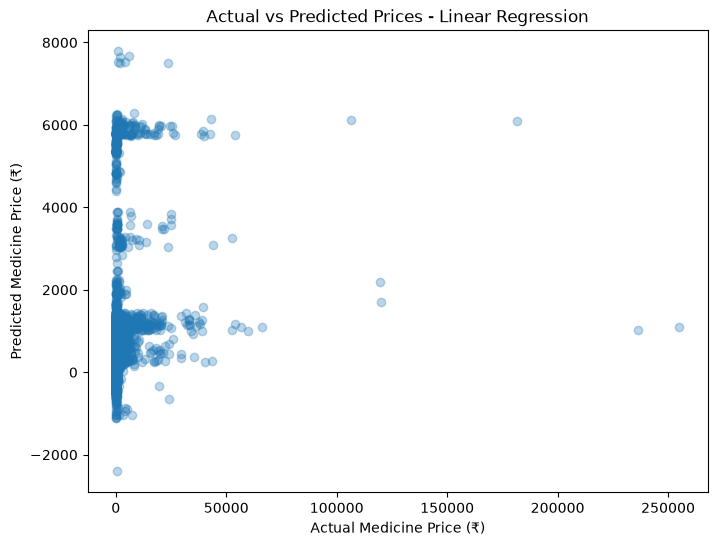

In [113]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Medicine Price (₹)")
plt.ylabel("Predicted Medicine Price (₹)")
plt.title("Actual vs Predicted Prices - Linear Regression")

plt.show()

### Train Linear Regression using log-transformed prices

In [114]:
# Apply log transformation to target variable
y_train_log = np.log1p(y_train)

# Initialize a new Linear Regression model
linear_model_log = LinearRegression()

# Train the model using log-transformed target
linear_model_log.fit(X_train_transformed, y_train_log)

print("Linear Regression with log transformation trained successfully!")

Linear Regression with log transformation trained successfully!


In [115]:
# Predict prices in log scale
y_pred_log = linear_model_log.predict(X_test_transformed)

# Convert predictions back to original price scale
y_pred_log = np.expm1(y_pred_log)

print("Log-transformed predictions generated successfully!")

Log-transformed predictions generated successfully!


In [116]:
# Calculate evaluation metrics
mae_log = mean_absolute_error(y_test, y_pred_log)
mse_log = mean_squared_error(y_test, y_pred_log)
rmse_log = np.sqrt(mse_log)
r2_log = r2_score(y_test, y_pred_log)

# Display results
print("Linear Regression with Log Transformation:")
print("------------------------------------------")
print("MAE:", mae_log)
print("MSE:", mse_log)
print("RMSE:", rmse_log)
print("R2 Score:", r2_log)

Linear Regression with Log Transformation:
------------------------------------------
MAE: 235.52465803236143
MSE: 47667035.00964678
RMSE: 6904.131734667783
R2 Score: -6.95928867670673


#### Let's investigate the prediction errors
Before moving to another algorithm, let's understand where the log model is failing.

In [117]:
# Create a DataFrame to inspect predictions
prediction_analysis = pd.DataFrame({
    "Actual_Price": np.asarray(y_test),
    "Predicted_Price": np.asarray(y_pred_log)
})

# Calculate absolute prediction error
prediction_analysis["Absolute_Error"] = abs(
    prediction_analysis["Actual_Price"] -
    prediction_analysis["Predicted_Price"]
)

# Display summary statistics
print("Prediction Summary:")
display(prediction_analysis.describe())

# Check negative predictions
print(
    "\nNegative predictions:",
    (prediction_analysis["Predicted_Price"] < 0).sum()
)

# Display 20 predictions with the largest errors
display(
    prediction_analysis.sort_values(
        by="Absolute_Error",
        ascending=False
    ).head(20)
)

Prediction Summary:


,Actual_Price,Predicted_Price,Absolute_Error
count,50795.000000,5.079500e+04,5.079500e+04
mean,259.399587,1.256938e+02,2.355247e+02
std,2447.238048,6.460073e+03,6.900181e+03
min,1.250000,2.419425e+01,9.794027e-05
25%,48.000000,6.723085e+01,1.698480e+01
50%,79.500000,8.432615e+01,3.821034e+01
75%,140.000000,1.037144e+02,7.563330e+01
max,255150.000000,1.455880e+06,1.455406e+06



Negative predictions: 0


,Actual_Price,Predicted_Price,Absolute_Error
25897,474.00,1.455880e+06,1.455406e+06
25730,255150.00,8.127521e+01,2.550687e+05
50675,236500.00,8.057581e+01,2.364194e+05
44366,181765.00,4.397012e+02,1.813253e+05
46577,120000.00,2.756598e+02,1.197243e+05
13571,119500.00,2.602379e+02,1.192398e+05
40682,106270.25,5.154820e+02,1.057548e+05
3851,66156.25,1.671631e+02,6.598909e+04
46038,59981.60,9.415059e+01,5.988745e+04
28390,56693.00,8.043225e+01,5.661257e+04


#### Investigate the extreme prediction

In [118]:
# Recreate prediction analysis with original test indexes
prediction_analysis = pd.DataFrame({
    "Actual_Price": np.asarray(y_test),
    "Predicted_Price": np.asarray(y_pred_log)
}, index=y_test.index)

prediction_analysis["Absolute_Error"] = abs(
    prediction_analysis["Actual_Price"] -
    prediction_analysis["Predicted_Price"]
)

# Identify the 20 largest prediction errors
worst_predictions = prediction_analysis.nlargest(
    20, "Absolute_Error"
)

# Display the corresponding medicine details
investigation_columns = [
    "brand_name",
    "manufacturer_clean",
    "dosage_form",
    "primary_ingredient",
    "therapeutic_class",
    "pack_size_final",
    "strength_value",
    "strength_unit"
]

display(
    worst_predictions.join(df[investigation_columns])
)

,Actual_Price,Predicted_Price,Absolute_Error,brand_name,manufacturer_clean,dosage_form,primary_ingredient,therapeutic_class,pack_size_final,strength_value,strength_unit
242870,474.00,1.455880e+06,1.455406e+06,Winpert Capsule,Emcure Pharmaceuticals Ltd,capsule,Pancreatin,other,10.0,25000.0,mg
175276,255150.00,8.127521e+01,2.550687e+05,Perjeta 420mg Injection,Roche Products India Pvt Ltd,injection,Pertuzumab,other,14.0,30.0,mg
115726,236500.00,8.057581e+01,2.364194e+05,Keytruda Injection,Msd Pharmaceuticals Pvt Ltd,injection,Pembrolizumab,other,4.0,100.0,mg
58222,181765.00,4.397012e+02,1.813253e+05,Calquence 100mg Capsule,Astrazeneca,capsule,Acalabrutinib,other,12.0,100.0,mg
238284,120000.00,2.756598e+02,1.197243e+05,VyndaMx 61mg Soft Gelatin Capsule,Pfizer Ltd,capsule,Tafamidis,other,30.0,61.0,mg
185232,119500.00,2.602379e+02,1.192398e+05,Ronapreve 120mg Injection Combi Pack,Cipla Ltd,other,Casirivimab,other,1.0,120.0,mg
48988,106270.25,5.154820e+02,1.057548e+05,Crizalk 250mg Capsule,Pfizer Ltd,capsule,Crizotinib,other,60.0,250.0,mg
104209,66156.25,1.671631e+02,6.598909e+04,Herclon Injection,Roche Products India Pvt Ltd,injection,Trastuzumab,other,1.0,440.0,mg
36099,59981.60,9.415059e+01,5.988745e+04,Canmab 440mg Injection,Biocon,injection,Trastuzumab,other,1.0,440.0,mg
72923,56693.00,8.043225e+01,5.661257e+04,Eylea 40mg/ml Injection,Bayer Zydus Pharma Pvt Ltd,injection,Aflibercept,other,1.0,40.0,mg


##### Investigate the Winpert prediction first

In [119]:
# Inspect the Winpert Capsule record
display(
    df.loc[
        [242870],
        [
            "brand_name",
            "price_inr",
            "primary_ingredient",
            "manufacturer_clean",
            "dosage_form",
            "therapeutic_class",
            "pack_size_final",
            "strength_value",
            "strength_unit",
            "strength_type",
            "denominator_value",
            "denominator_unit"
        ]
    ]
)

,brand_name,price_inr,primary_ingredient,manufacturer_clean,dosage_form,therapeutic_class,pack_size_final,strength_value,strength_unit,strength_type,denominator_value,denominator_unit
242870,Winpert Capsule,474.0,Pancreatin,Emcure Pharmaceuticals Ltd,capsule,other,10.0,25000.0,mg,simple,NaN,NaN


In [120]:
display(
    df.loc[
        242870,
        [
            "brand_name",
            "primary_strength",
            "packaging_raw",
            "pack_size",
            "package_quantity",
            "pack_size_final",
            "price_inr"
        ]
    ].to_frame("Value")
)

,Value
brand_name,Winpert Capsule
primary_strength,25000mg
packaging_raw,strip of 10 capsules
pack_size,10.0
package_quantity,10.0
pack_size_final,10.0
price_inr,474.0


#### Let's inspect the Linear Regression coefficients

In [121]:
# Get feature names manually
feature_names = []

# Numerical features
feature_names.extend(numerical_columns)

# Denominator features
feature_names.extend(
    ["denominator_value", "has_denominator"]
)

# One-hot encoded features
feature_names.extend(
    preprocessor.named_transformers_["onehot"]
    .get_feature_names_out(onehot_columns)
)

# Frequency encoded features
feature_names.extend(frequency_columns)

# Create coefficient DataFrame
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model.coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

display(
    coefficients.sort_values(
        by="Absolute_Coefficient",
        ascending=False
    ).head(20)
)

,Feature,Coefficient,Absolute_Coefficient
74,denominator_unit_ml,25289.877024,25289.877024
51,package_type_penfill,7112.404236,7112.404236
73,denominator_unit_g,-5565.964737,5565.964737
26,pack_unit_strip,4120.396177,4120.396177
49,package_type_kit,3495.050125,3495.050125
42,package_type_box,2852.478731,2852.478731
52,package_type_pouch,2657.661645,2657.661645
57,package_type_sachet,-2354.130137,2354.130137
56,package_type_roll,-1714.634394,1714.634394
41,package_type_bottle,-1469.163897,1469.163897


In [122]:
# Compare coefficients of both models

coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Original_LR": linear_model.coef_,
    "Log_Transformed_LR": linear_model_log.coef_
})

coefficient_comparison["Original_Absolute"] = (
    coefficient_comparison["Original_LR"].abs()
)

coefficient_comparison["Log_Absolute"] = (
    coefficient_comparison["Log_Transformed_LR"].abs()
)

display(
    coefficient_comparison.sort_values(
        by="Original_Absolute",
        ascending=False
    ).head(20)
)

,Feature,Original_LR,Log_Transformed_LR,Original_Absolute,Log_Absolute
74,denominator_unit_ml,25289.877024,35.008534,25289.877024,35.008534
51,package_type_penfill,7112.404236,2.483606,7112.404236,2.483606
73,denominator_unit_g,-5565.964737,6.933933,5565.964737,6.933933
26,pack_unit_strip,4120.396177,0.890716,4120.396177,0.890716
49,package_type_kit,3495.050125,1.866678,3495.050125,1.866678
42,package_type_box,2852.478731,1.526879,2852.478731,1.526879
52,package_type_pouch,2657.661645,1.656499,2657.661645,1.656499
57,package_type_sachet,-2354.130137,-0.653197,2354.130137,0.653197
56,package_type_roll,-1714.634394,-1.523816,1714.634394,1.523816
41,package_type_bottle,-1469.163897,-0.829741,1469.163897,0.829741


## Decision Tree Regressor

In [123]:
from sklearn.tree import DecisionTreeRegressor

# Initialize Decision Tree model
dt_model = DecisionTreeRegressor(
    random_state=42
)

# Train the model
dt_model.fit(X_train_transformed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [124]:
# Make predictions using Decision Tree
y_pred_dt = dt_model.predict(X_test_transformed)

print("Decision Tree predictions generated successfully!")

Decision Tree predictions generated successfully!


In [125]:
# Calculate evaluation metrics
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# Display results
print("Decision Tree Performance:")
print("--------------------------")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Performance:
--------------------------
MAE: 178.01265344140887
MSE: 13511479.21179117
RMSE: 3675.796405106133
R2 Score: -1.2561034785193517


### Check whether the Decision Tree is overfitting

In [126]:
# Predict on training data
y_train_pred_dt = dt_model.predict(X_train_transformed)

# Training metrics
train_mae_dt = mean_absolute_error(y_train, y_train_pred_dt)
train_r2_dt = r2_score(y_train, y_train_pred_dt)

# Testing metrics
test_mae_dt = mean_absolute_error(y_test, y_pred_dt)
test_r2_dt = r2_score(y_test, y_pred_dt)

# Display comparison
print("Decision Tree - Train vs Test")
print("--------------------------------")
print("Training MAE:", train_mae_dt)
print("Testing MAE:", test_mae_dt)
print("Training R2:", train_r2_dt)
print("Testing R2:", test_r2_dt)

Decision Tree - Train vs Test
--------------------------------
Training MAE: 17.30739759285537
Testing MAE: 178.01265344140887
Training R2: 0.9975337093230697
Testing R2: -1.2561034785193517


### Decision Tree - Hyperparameter Tuning

In [127]:
# Initialize Decision Tree with limited depth
dt_model_tuned = DecisionTreeRegressor(
    max_depth=15,
    random_state=42
)

# Train the model
dt_model_tuned.fit(X_train_transformed, y_train)

print("Tuned Decision Tree model trained successfully!")

Tuned Decision Tree model trained successfully!


#### Compare training and testing performance

In [129]:
# Training predictions
y_train_pred_dt_tuned = dt_model_tuned.predict(
    X_train_transformed
)

# Testing predictions
y_test_pred_dt_tuned = dt_model_tuned.predict(
    X_test_transformed
)

# Calculate metrics
train_mae = mean_absolute_error(y_train, y_train_pred_dt_tuned)
test_mae = mean_absolute_error(y_test, y_test_pred_dt_tuned)

train_r2 = r2_score(y_train, y_train_pred_dt_tuned)
test_r2 = r2_score(y_test, y_test_pred_dt_tuned)

# Display results
print("Tuned Decision Tree - Train vs Test")
print("-----------------------------------")
print("Training MAE:", train_mae)
print("Testing MAE:", test_mae)
print("Training R2:", train_r2)
print("Testing R2:", test_r2)

Tuned Decision Tree - Train vs Test
-----------------------------------
Training MAE: 79.95444849851998
Testing MAE: 183.6306196857729
Training R2: 0.9721086266020981
Testing R2: -0.9706922009349441


In [131]:
# Initialize a more restrictive Decision Tree
dt_model_tuned_2 = DecisionTreeRegressor(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# Train the model
dt_model_tuned_2.fit(X_train_transformed, y_train)

# Generate predictions
y_train_pred_dt_2 = dt_model_tuned_2.predict(X_train_transformed)
y_test_pred_dt_2 = dt_model_tuned_2.predict(X_test_transformed)

# Calculate metrics
print("Decision Tree - Tuned Model 2")
print("--------------------------------")
print("Training MAE:", mean_absolute_error(y_train, y_train_pred_dt_2))
print("Testing MAE:", mean_absolute_error(y_test, y_test_pred_dt_2))
print("Training R2:", r2_score(y_train, y_train_pred_dt_2))
print("Testing R2:", r2_score(y_test, y_test_pred_dt_2))

Decision Tree - Tuned Model 2
--------------------------------
Training MAE: 219.02354842357556
Testing MAE: 223.42989328297583
Training R2: 0.35490979301661274
Testing R2: 0.2133564888906555


In [132]:
# Calculate MSE and RMSE
mse_dt_2 = mean_squared_error(y_test, y_test_pred_dt_2)
rmse_dt_2 = np.sqrt(mse_dt_2)

print("Decision Tree Tuned Model 2")
print("----------------------------")
print("MSE:", mse_dt_2)
print("RMSE:", rmse_dt_2)

Decision Tree Tuned Model 2
----------------------------
MSE: 4711094.83613748
RMSE: 2170.505663696246


## Random Forest Regressor

In [133]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_transformed,y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [134]:
# Generate Random Forest predictions
y_pred_rf = rf_model.predict(X_test_transformed)

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


In [135]:
# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Display results
print("Random Forest Performance:")
print("--------------------------")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Performance:
--------------------------
MAE: 155.60102503334105
MSE: 4620779.350088114
RMSE: 2149.5998116133414
R2 Score: 0.2284370791832656


#### Check whether Random Forest is overfitting

In [137]:
# Generate predictions on training data
y_train_pred_rf = rf_model.predict(X_train_transformed)

# Calculate training metrics
train_mae_rf = mean_absolute_error(y_train, y_train_pred_rf)
train_r2_rf = r2_score(y_train, y_train_pred_rf)

# Display comparison
print("Random Forest - Training vs Testing")
print("-----------------------------------")
print("Training MAE:", train_mae_rf)
print("Testing MAE:", mae_rf)
print("Training R2:", train_r2_rf)
print("Testing R2:", r2_rf)

Random Forest - Training vs Testing
-----------------------------------
Training MAE: 67.23095622678316
Testing MAE: 155.60102503334105
Training R2: 0.9042663529499754
Testing R2: 0.2284370791832656


## Alternative Experiment: One-Hot Encoding for Primary Ingredient

In [193]:
# Train Random Forest with One-Hot Encoded ingredients

rf_model_onehot = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model_onehot.fit(X_train_onehot, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [194]:
# Generate predictions using One-Hot Random Forest

y_pred_onehot = rf_model_onehot.predict(X_test_onehot)

# Evaluate model performance

mae_onehot = mean_absolute_error(y_test, y_pred_onehot)

mse_onehot = mean_squared_error(y_test, y_pred_onehot)

rmse_onehot = np.sqrt(mse_onehot)

r2_onehot = r2_score(y_test, y_pred_onehot)

print("One-Hot Random Forest Performance")
print("---------------------------------")
print("MAE:", mae_onehot)
print("MSE:", mse_onehot)
print("RMSE:", rmse_onehot)
print("R2 Score:", r2_onehot)

One-Hot Random Forest Performance
---------------------------------
MAE: 242.7362450660659
MSE: 5136987.556595729
RMSE: 2266.4923464674944
R2 Score: 0.14224228791824056


In [195]:
# Compare original and alternative Random Forest models

encoding_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - Frequency Encoding",
        "Random Forest - One-Hot Ingredient Encoding"
    ],
    "MAE": [
        176.3743,
        mae_onehot
    ],
    "RMSE": [
        2063.5917,
        rmse_onehot
    ],
    "R2 Score": [
        0.2889,
        r2_onehot
    ]
})

encoding_comparison

,Model,MAE,RMSE,R2 Score
0,Random Forest - Frequency Encoding,176.374300,2063.591700,0.288900
1,Random Forest - One-Hot Ingredient Encoding,242.736245,2266.492346,0.142242


### Tune Random Forest

In [218]:
rf_tuned = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train_transformed, y_train)

y_pred_rf_tuned = rf_tuned.predict(X_test_transformed)

In [140]:
# Generate predictions using tuned Random Forest
y_pred_rf_tuned = rf_model_tuned.predict(X_test_transformed)

print("Tuned Random Forest predictions generated successfully!")

Tuned Random Forest predictions generated successfully!


In [219]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_rf_tuned)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned))
r2 = r2_score(y_test, y_pred_rf_tuned)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 172.0648503070327
RMSE: 2059.44893308515
R2 Score: 0.29179633044146325


#### Create a prediction comparison DataFrame

In [220]:
# Compare actual and predicted prices

prediction_df = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred_rf_tuned
})

# Calculate prediction errors
prediction_df["Error"] = (
    prediction_df["Actual_Price"] -
    prediction_df["Predicted_Price"]
)

prediction_df["Absolute_Error"] = prediction_df["Error"].abs()

prediction_df.head(10)

,Actual_Price,Predicted_Price,Error,Absolute_Error
0,42.0,107.171306,-65.171306,65.171306
1,120.0,112.429452,7.570548,7.570548
2,27.0,112.524041,-85.524041,85.524041
3,52.0,51.720341,0.279659,0.279659
4,45.0,4061.522832,-4016.522832,4016.522832
5,78.0,66.093042,11.906958,11.906958
6,7.7,34.189665,-26.489665,26.489665
7,125.0,116.087435,8.912565,8.912565
8,173.9,116.761507,57.138493,57.138493
9,63.0,84.921651,-21.921651,21.921651


In [221]:
# Identify the 20 largest prediction errors

top_errors = prediction_df.sort_values(
    by="Absolute_Error",
    ascending=False
).head(20)

top_errors

,Actual_Price,Predicted_Price,Error,Absolute_Error
25730,255150.00,60246.615627,194903.384373,194903.384373
50675,236500.00,42114.194217,194385.805783,194385.805783
44366,181765.00,41934.929638,139830.070362,139830.070362
46577,120000.00,21164.760993,98835.239007,98835.239007
13571,119500.00,24322.536365,95177.463635,95177.463635
26845,83.67,80857.336921,-80773.666921,80773.666921
36694,20436.19,96929.281583,-76493.091583,76493.091583
25298,1786.25,70688.024786,-68901.774786,68901.774786
47426,750.79,66045.640138,-65294.850138,65294.850138
40829,130.30,47409.062745,-47278.762745,47278.762745


In [222]:
###Identify the medicines behind these errors
# Retrieve original features for the 20 largest prediction errors

top_error_details = X_test.reset_index(drop=True).iloc[
    top_errors.index
].copy()

top_error_details["Actual_Price"] = (
    y_test.reset_index(drop=True).iloc[top_errors.index].values
)

top_error_details["Predicted_Price"] = (
    y_pred_rf_tuned[top_errors.index]
)

top_error_details["Absolute_Error"] = (
    top_errors["Absolute_Error"].values
)

# Display relevant product information

top_error_details[
    [
        "primary_ingredient",
        "ingredient_combination",
        "manufacturer_clean",
        "dosage_form",
        "pack_size_final",
        "strength_value",
        "strength_unit",
        "Actual_Price",
        "Predicted_Price",
        "Absolute_Error"
    ]
]

,primary_ingredient,ingredient_combination,manufacturer_clean,dosage_form,pack_size_final,strength_value,strength_unit,Actual_Price,Predicted_Price,Absolute_Error
25730,Pertuzumab,pertuzumab,Roche Products India Pvt Ltd,injection,14.0,30.0,mg,255150.00,60246.615627,194903.384373
50675,Pembrolizumab,pembrolizumab,Msd Pharmaceuticals Pvt Ltd,injection,4.0,100.0,mg,236500.00,42114.194217,194385.805783
44366,Acalabrutinib,acalabrutinib,Astrazeneca,capsule,12.0,100.0,mg,181765.00,41934.929638,139830.070362
46577,Tafamidis,tafamidis,Pfizer Ltd,capsule,30.0,61.0,mg,120000.00,21164.760993,98835.239007
13571,Casirivimab,casirivimab + imdevimab,Cipla Ltd,other,1.0,120.0,mg,119500.00,24322.536365,95177.463635
26845,Epsilon Aminocaproic Acid,epsilon aminocaproic acid,Samarth Life Sciences Pvt Ltd,injection,1.0,500.0,mg,83.67,80857.336921,80773.666921
36694,Tocilizumab,tocilizumab,Roche Products India Pvt Ltd,injection,1.0,200.0,mg,20436.19,96929.281583,76493.091583
25298,Molgramostim,molgramostim,Sun Pharmaceutical Industries Ltd,injection,1.0,400.0,mg,1786.25,70688.024786,68901.774786
47426,Glucagon,glucagon,Novo Nordisk India Pvt Ltd,injection,1.0,1.0,mg,750.79,66045.640138,65294.850138
40829,Nitroprusside,nitroprusside,Neon Laboratories Ltd,injection,1.0,50.0,mg,130.30,47409.062745,47278.762745


#### Investigate ingredient-level price distribution
Before changing the model, let's investigate whether these ingredients have enough examples in the training dataset and what their historical prices look like.

In [225]:
# Create training ingredient analysis

ingredient_train_analysis = X_train[
    ["primary_ingredient"]
].copy()

ingredient_train_analysis["price_inr"] = y_train.values

# Normalize ingredient names
ingredient_train_analysis["ingredient_key"] = (
    ingredient_train_analysis["primary_ingredient"]
    .astype(str)
    .str.strip()
    .str.casefold()
)

# Calculate ingredient-level price statistics
ingredient_price_stats = (
    ingredient_train_analysis
    .groupby("ingredient_key")["price_inr"]
    .agg(
        product_count="count",
        median_price="median",
        mean_price="mean",
        min_price="min",
        max_price="max"
    )
    .reset_index()
)

# Normalize ingredient names in prediction error data
error_analysis = top_error_details.copy()

error_analysis["ingredient_key"] = (
    error_analysis["primary_ingredient"]
    .astype(str)
    .str.strip()
    .str.casefold()
)

# Merge training statistics with prediction errors
error_analysis = error_analysis.merge(
    ingredient_price_stats,
    on="ingredient_key",
    how="left"
)

# Display results
error_analysis[
    [
        "primary_ingredient",
        "product_count",
        "median_price",
        "mean_price",
        "min_price",
        "max_price",
        "Actual_Price",
        "Predicted_Price",
        "Absolute_Error"
    ]
]

,primary_ingredient,product_count,median_price,mean_price,min_price,max_price,Actual_Price,Predicted_Price,Absolute_Error
0,Pertuzumab,NaN,NaN,NaN,NaN,NaN,255150.00,60246.615627,194903.384373
1,Pembrolizumab,NaN,NaN,NaN,NaN,NaN,236500.00,42114.194217,194385.805783
2,Acalabrutinib,NaN,NaN,NaN,NaN,NaN,181765.00,41934.929638,139830.070362
3,Tafamidis,NaN,NaN,NaN,NaN,NaN,120000.00,21164.760993,98835.239007
4,Casirivimab,NaN,NaN,NaN,NaN,NaN,119500.00,24322.536365,95177.463635
5,Epsilon Aminocaproic Acid,NaN,NaN,NaN,NaN,NaN,83.67,80857.336921,80773.666921
6,Tocilizumab,2.0,28189.95,28189.950000,8112.00,48267.90,20436.19,96929.281583,76493.091583
7,Molgramostim,1.0,6500.00,6500.000000,6500.00,6500.00,1786.25,70688.024786,68901.774786
8,Glucagon,2.0,1002.50,1002.500000,990.00,1015.00,750.79,66045.640138,65294.850138
9,Nitroprusside,NaN,NaN,NaN,NaN,NaN,130.30,47409.062745,47278.762745


In [226]:
from difflib import get_close_matches

# Get unique normalized ingredient names from training data
training_ingredients = (
    ingredient_train_analysis["ingredient_key"]
    .dropna()
    .unique()
    .tolist()
)

# Find ingredients that did not match exactly
unmatched_ingredients = error_analysis[
    error_analysis["product_count"].isna()
]["ingredient_key"].unique()

# Find similar names
for ingredient in unmatched_ingredients:

    matches = get_close_matches(
        ingredient,
        training_ingredients,
        n=5,
        cutoff=0.75
    )

    print(f"\nTest ingredient: {ingredient}")
    print("Similar training ingredients:", matches)


Test ingredient: pertuzumab
Similar training ingredients: ['trastuzumab']

Test ingredient: pembrolizumab
Similar training ingredients: ['mepolizumab']

Test ingredient: acalabrutinib
Similar training ingredients: []

Test ingredient: tafamidis
Similar training ingredients: []

Test ingredient: casirivimab
Similar training ingredients: []

Test ingredient: epsilon aminocaproic acid
Similar training ingredients: []

Test ingredient: nitroprusside
Similar training ingredients: ['itopride']

Test ingredient: carbenicillin
Similar training ingredients: ['penicillin', 'varenicline', 'ticarcillin']


#### Let's inspect the unmatched products

In [227]:
# Inspect unmatched ingredients and their product features

unmatched_product_details = error_analysis[
    error_analysis["product_count"].isna()
][
    [
        "primary_ingredient",
        "ingredient_combination",
        "manufacturer_clean",
        "dosage_form",
        "pack_size_final",
        "strength_value",
        "strength_unit",
        "therapeutic_class",
        "Actual_Price",
        "Predicted_Price",
        "Absolute_Error"
    ]
]

unmatched_product_details

,primary_ingredient,ingredient_combination,manufacturer_clean,dosage_form,pack_size_final,strength_value,strength_unit,therapeutic_class,Actual_Price,Predicted_Price,Absolute_Error
0,Pertuzumab,pertuzumab,Roche Products India Pvt Ltd,injection,14.0,30.0,mg,other,255150.00,60246.615627,194903.384373
1,Pembrolizumab,pembrolizumab,Msd Pharmaceuticals Pvt Ltd,injection,4.0,100.0,mg,other,236500.00,42114.194217,194385.805783
2,Acalabrutinib,acalabrutinib,Astrazeneca,capsule,12.0,100.0,mg,other,181765.00,41934.929638,139830.070362
3,Tafamidis,tafamidis,Pfizer Ltd,capsule,30.0,61.0,mg,other,120000.00,21164.760993,98835.239007
4,Casirivimab,casirivimab + imdevimab,Cipla Ltd,other,1.0,120.0,mg,other,119500.00,24322.536365,95177.463635
5,Epsilon Aminocaproic Acid,epsilon aminocaproic acid,Samarth Life Sciences Pvt Ltd,injection,1.0,500.0,mg,other,83.67,80857.336921,80773.666921
9,Nitroprusside,nitroprusside,Neon Laboratories Ltd,injection,1.0,50.0,mg,other,130.30,47409.062745,47278.762745
10,Nitroprusside,nitroprusside,Troikaa Pharmaceuticals Ltd,injection,1.0,50.0,mg,other,141.50,47409.062745,47267.562745
14,Carbenicillin,carbenicillin,Lyka Labs,injection,1.0,1.0,g,other,25.00,41314.378203,41289.378203


In [228]:
# Create actual price ranges

prediction_df["Price_Range"] = pd.cut(
    prediction_df["Actual_Price"],
    bins=[-1, 100, 500, 5000, 25000, float("inf")],
    labels=[
        "0-100",
        "100-500",
        "500-5000",
        "5000-25000",
        "Above 25000"
    ]
)

# Calculate prediction errors for each price range

price_range_analysis = (
    prediction_df
    .groupby("Price_Range", observed=False)
    .agg(
        product_count=("Actual_Price", "count"),
        mean_actual_price=("Actual_Price", "mean"),
        mean_predicted_price=("Predicted_Price", "mean"),
        MAE=("Absolute_Error", "mean"),
        median_absolute_error=("Absolute_Error", "median")
    )
    .reset_index()
)

price_range_analysis

,Price_Range,product_count,mean_actual_price,mean_predicted_price,MAE,median_absolute_error
0,0-100,31657,55.019952,108.483400,58.400541,17.866110
1,100-500,17095,189.154816,221.867622,107.938667,34.458009
2,500-5000,1721,1453.113626,1980.982488,1136.112667,376.511433
3,5000-25000,276,11338.359167,10111.546560,5778.410055,3224.117412
4,Above 25000,46,55883.437826,28976.898120,32520.555716,23160.996335


In [229]:
# Calculate prediction bias for each price range

price_range_analysis["Prediction_Bias"] = (
    price_range_analysis["mean_predicted_price"]
    - price_range_analysis["mean_actual_price"]
)

price_range_analysis["Bias_Percentage"] = (
    price_range_analysis["Prediction_Bias"]
    / price_range_analysis["mean_actual_price"]
) * 100

price_range_analysis

,Price_Range,product_count,mean_actual_price,mean_predicted_price,MAE,median_absolute_error,Prediction_Bias,Bias_Percentage
0,0-100,31657,55.019952,108.483400,58.400541,17.866110,53.463449,97.171021
1,100-500,17095,189.154816,221.867622,107.938667,34.458009,32.712806,17.294197
2,500-5000,1721,1453.113626,1980.982488,1136.112667,376.511433,527.868863,36.326744
3,5000-25000,276,11338.359167,10111.546560,5778.410055,3224.117412,-1226.812607,-10.820019
4,Above 25000,46,55883.437826,28976.898120,32520.555716,23160.996335,-26906.539706,-48.147610


#### Train Random Forest with log-transformed target

In [230]:
# Train Random Forest with log-transformed target

rf_log_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Transform target using log1p
y_train_log = np.log1p(y_train)

# Train model
rf_log_model.fit(X_train_transformed, y_train_log)

# Predict on test data
y_pred_log = rf_log_model.predict(X_test_transformed)

# Convert predictions back to original price scale
y_pred_rf_log = np.expm1(y_pred_log)

# Evaluate model
mae_log = mean_absolute_error(y_test, y_pred_rf_log)
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_rf_log))
r2_log = r2_score(y_test, y_pred_rf_log)

print("Random Forest with Log-Transformed Target")
print("-----------------------------------------")
print("MAE:", mae_log)
print("RMSE:", rmse_log)
print("R2 Score:", r2_log)

Random Forest with Log-Transformed Target
-----------------------------------------
MAE: 132.8306794446192
RMSE: 2241.3457756459948
R2 Score: 0.1611702213311378


In [231]:
# Compare Random Forest models

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - Original Target",
        "Random Forest - Log Transformed Target"
    ],
    "MAE": [
        172.064850,
        mae_log
    ],
    "RMSE": [
        2059.448934,
        rmse_log
    ],
    "R2 Score": [
        0.291796,
        r2_log
    ]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Random Forest - Original Target,172.064850,2059.448934,0.291796
1,Random Forest - Log Transformed Target,132.830679,2241.345776,0.161170


#### Check for duplicate products across train and test

In [234]:
# Check product overlap using original dataset indices

train_products = set(df.loc[X_train.index, "product_id"])
test_products = set(df.loc[X_test.index, "product_id"])

overlapping_products = train_products.intersection(test_products)

print("Training products:", len(train_products))
print("Testing products:", len(test_products))
print("Overlapping products:", len(overlapping_products))

Training products: 203178
Testing products: 50795
Overlapping products: 0


In [235]:
# Check brand overlap between training and testing datasets

train_brands = set(df.loc[X_train.index, "brand_name"].dropna())
test_brands = set(df.loc[X_test.index, "brand_name"].dropna())

overlapping_brands = train_brands.intersection(test_brands)

print("Unique training brands:", len(train_brands))
print("Unique testing brands:", len(test_brands))
print("Overlapping brands:", len(overlapping_brands))

Unique training brands: 200239
Unique testing brands: 50589
Overlapping brands: 1430


In [236]:
# Check manufacturer overlap between training and testing datasets

train_manufacturers = set(
    df.loc[X_train.index, "manufacturer_clean"].dropna()
)

test_manufacturers = set(
    df.loc[X_test.index, "manufacturer_clean"].dropna()
)

overlapping_manufacturers = (
    train_manufacturers.intersection(test_manufacturers)
)

print("Unique training manufacturers:", len(train_manufacturers))
print("Unique testing manufacturers:", len(test_manufacturers))
print("Overlapping manufacturers:", len(overlapping_manufacturers))

Unique training manufacturers: 7376
Unique testing manufacturers: 5662
Overlapping manufacturers: 5390


### Create a manufacturer-based split

In [237]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone

# Define features and target
X = df[selected_features]
y = df[target]

# Use manufacturer as the grouping variable
groups = df["manufacturer_clean"].fillna("Unknown")

# Create an 80:20 group-based split
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

# Create training and testing datasets
X_group_train = X.iloc[train_idx]
X_group_test = X.iloc[test_idx]

y_group_train = y.iloc[train_idx]
y_group_test = y.iloc[test_idx]

print("Training records:", len(X_group_train))
print("Testing records:", len(X_group_test))

print(
    "Overlapping manufacturers:",
    len(
        set(groups.iloc[train_idx])
        .intersection(set(groups.iloc[test_idx]))
    )
)

Training records: 205381
Testing records: 48592
Overlapping manufacturers: 0


### Preprocess the group-based datasets

In [238]:
# Create a fresh copy of the preprocessing pipeline

group_preprocessor = clone(preprocessor)

# Fit on training data and transform
X_group_train_transformed = group_preprocessor.fit_transform(
    X_group_train
)

# Transform testing data without fitting again
X_group_test_transformed = group_preprocessor.transform(
    X_group_test
)

print("Training transformed shape:", X_group_train_transformed.shape)
print("Testing transformed shape:", X_group_test_transformed.shape)

Training transformed shape: (205381, 76)
Testing transformed shape: (48592, 76)


In [239]:
# Train Random Forest on manufacturer-based split

rf_group_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_group_model.fit(
    X_group_train_transformed,
    y_group_train
)

# Make predictions
y_pred_group = rf_group_model.predict(
    X_group_test_transformed
)

# Evaluate the model
group_mae = mean_absolute_error(
    y_group_test,
    y_pred_group
)

group_rmse = np.sqrt(
    mean_squared_error(y_group_test, y_pred_group)
)

group_r2 = r2_score(
    y_group_test,
    y_pred_group
)

print("Random Forest - Manufacturer-Based Split")
print("----------------------------------------")
print("MAE:", group_mae)
print("RMSE:", group_rmse)
print("R2 Score:", group_r2)

Random Forest - Manufacturer-Based Split
----------------------------------------
MAE: 255.44958117311822
RMSE: 4180.366416442998
R2 Score: 0.23355484321552133


In [240]:
# Compare target price distributions

target_comparison = pd.DataFrame({
    "Random_Split_Test": y_test.describe(),
    "Manufacturer_Split_Test": y_group_test.describe()
})

target_comparison

,Random_Split_Test,Manufacturer_Split_Test
count,50795.000000,48592.000000
mean,259.399587,338.069628
std,2447.238048,4775.053885
min,1.250000,1.160000
25%,48.000000,48.800000
50%,79.500000,79.000000
75%,140.000000,138.000000
max,255150.000000,396725.000000


In [241]:
# Create prediction results for manufacturer-based split

group_prediction_df = pd.DataFrame({
    "Actual_Price": y_group_test.values,
    "Predicted_Price": y_pred_group
})

group_prediction_df["Absolute_Error"] = (
    group_prediction_df["Actual_Price"]
    - group_prediction_df["Predicted_Price"]
).abs()

# Define common price ranges
price_bins = [-1, 100, 500, 5000, 25000, float("inf")]

price_labels = [
    "0-100",
    "100-500",
    "500-5000",
    "5000-25000",
    "Above 25000"
]

# Assign price ranges
prediction_df["Price_Range"] = pd.cut(
    prediction_df["Actual_Price"],
    bins=price_bins,
    labels=price_labels
)

group_prediction_df["Price_Range"] = pd.cut(
    group_prediction_df["Actual_Price"],
    bins=price_bins,
    labels=price_labels
)

# Calculate MAE by price range
random_range_mae = (
    prediction_df.groupby("Price_Range", observed=False)
    ["Absolute_Error"].mean()
)

group_range_mae = (
    group_prediction_df.groupby("Price_Range", observed=False)
    ["Absolute_Error"].mean()
)

# Combine results
range_comparison = pd.DataFrame({
    "Random_Split_MAE": random_range_mae,
    "Manufacturer_Split_MAE": group_range_mae
})

range_comparison

,Random_Split_MAE,Manufacturer_Split_MAE
Price_Range,,
0-100,58.400541,57.953783
100-500,107.938667,123.388485
500-5000,1136.112667,1271.753665
5000-25000,5778.410055,6425.230102
Above 25000,32520.555716,61435.050104


In [242]:
# Count products in each price range

group_price_counts = (
    group_prediction_df
    .groupby("Price_Range", observed=False)
    .agg(
        product_count=("Actual_Price", "count"),
        mean_actual_price=("Actual_Price", "mean"),
        median_actual_price=("Actual_Price", "median")
    )
    .reset_index()
)

group_price_counts

,Price_Range,product_count,mean_actual_price,median_actual_price
0,0-100,30794,55.771635,56.0
1,100-500,15966,186.597956,158.0
2,500-5000,1490,1500.299826,1048.5
3,5000-25000,259,11235.723977,9754.0
4,Above 25000,83,79341.269880,43949.0


# Final conclusions
1. The tuned Random Forest is our preferred model among the experiments conducted.
2. Ingredient combination engineering provided a modest improvement.
3. Log transformation reduced MAE but worsened RMSE and R².
4. The model performs better on lower-priced medicines.
5. Generalization to unseen manufacturers is more challenging, particularly for expensive medicines.
6. Extreme price values have a substantial influence on RMSE.

#### overfitting in tuned Random Forest

In [142]:
# Generate predictions on training data
y_train_pred_rf_tuned = rf_model_tuned.predict(X_train_transformed)

# Calculate training metrics
train_mae_rf_tuned = mean_absolute_error(y_train, y_train_pred_rf_tuned)
train_r2_rf_tuned = r2_score(y_train, y_train_pred_rf_tuned)

# Display comparison
print("Tuned Random Forest - Training vs Testing")
print("-----------------------------------------")
print("Training MAE:", train_mae_rf_tuned)
print("Testing MAE:", mae_rf_tuned)
print("Training R2:", train_r2_rf_tuned)
print("Testing R2:", r2_rf_tuned)

Tuned Random Forest - Training vs Testing
-----------------------------------------
Training MAE: 152.24273671091245
Testing MAE: 176.37431920924783
Training R2: 0.5111843223224115
Testing R2: 0.2889442130801585


## Gradient Boosting Regressor

In [144]:
from sklearn.ensemble import GradientBoostingRegressor

# Initialize Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train_transformed, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


# Generate Gradient Boosting predictions
y_pred_gb = gb_model.predict(X_test_transformed)

print("Gradient Boosting predictions generated successfully!")

In [146]:
# Calculate evaluation metrics
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

# Display results
print("Gradient Boosting Performance:")
print("--------------------------------")
print("MAE:", mae_gb)
print("MSE:", mse_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Gradient Boosting Performance:
--------------------------------
MAE: 267.692262312322
MSE: 4673375.177815098
RMSE: 2161.7990604621646
R2 Score: 0.21965479650122577


#### Check Gradient Boosting overfitting

In [148]:
# Generate predictions on training data
y_train_pred_gb = gb_model.predict(X_train_transformed)

# Calculate training metrics
train_mae_gb = mean_absolute_error(y_train, y_train_pred_gb)
train_r2_gb = r2_score(y_train, y_train_pred_gb)

# Display comparison
print("Gradient Boosting - Training vs Testing")
print("---------------------------------------")
print("Training MAE:", train_mae_gb)
print("Testing MAE:", mae_gb)
print("Training R2:", train_r2_gb)
print("Testing R2:", r2_gb)

Gradient Boosting - Training vs Testing
---------------------------------------
Training MAE: 266.4597390262325
Testing MAE: 267.692262312322
Training R2: 0.38110862185085104
Testing R2: 0.21965479650122577


In [149]:
# Initialize tuned Gradient Boosting
gb_model_tuned = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42
)

# Train the tuned model
gb_model_tuned.fit(X_train_transformed, y_train)

print("Tuned Gradient Boosting model trained successfully!")

Tuned Gradient Boosting model trained successfully!


In [150]:
# Generate predictions using tuned Gradient Boosting
y_pred_gb_tuned = gb_model_tuned.predict(X_test_transformed)

print("Tuned Gradient Boosting predictions generated successfully!")

Tuned Gradient Boosting predictions generated successfully!


In [151]:
# Calculate evaluation metrics
mae_gb_tuned = mean_absolute_error(y_test, y_pred_gb_tuned)
mse_gb_tuned = mean_squared_error(y_test, y_pred_gb_tuned)
rmse_gb_tuned = np.sqrt(mse_gb_tuned)
r2_gb_tuned = r2_score(y_test, y_pred_gb_tuned)

# Display results
print("Tuned Gradient Boosting Performance:")
print("------------------------------------")
print("MAE:", mae_gb_tuned)
print("MSE:", mse_gb_tuned)
print("RMSE:", rmse_gb_tuned)
print("R2 Score:", r2_gb_tuned)

Tuned Gradient Boosting Performance:
------------------------------------
MAE: 271.4338268783989
MSE: 4783151.787878238
RMSE: 2187.041789239117
R2 Score: 0.2013246501167073


## K-Nearest Neighbors (KNN)

In [152]:
from sklearn.neighbors import KNeighborsRegressor

# Initialize KNN Regressor
knn_model = KNeighborsRegressor(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1
)

# Train the model
knn_model.fit(X_train_transformed, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [153]:
# Generate KNN predictions
y_pred_knn = knn_model.predict(X_test_transformed)

print("KNN predictions generated successfully!")

KNN predictions generated successfully!


In [154]:
# Calculate evaluation metrics
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_test, y_pred_knn)

# Display results
print("KNN Performance:")
print("----------------")
print("MAE:", mae_knn)
print("MSE:", mse_knn)
print("RMSE:", rmse_knn)
print("R2 Score:", r2_knn)

KNN Performance:
----------------
MAE: 185.0895174606767
MSE: 6048186.321345052
RMSE: 2459.306064999851
R2 Score: -0.009906760350247401


## XGBoost Regressor

In [155]:
from xgboost import XGBRegressor

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    objective="reg:squarederror"
)

# Train the model
xgb_model.fit(X_train_transformed, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [156]:
# Generate XGBoost predictions
y_pred_xgb = xgb_model.predict(X_test_transformed)

print("XGBoost predictions generated successfully!")

XGBoost predictions generated successfully!


In [157]:
# Calculate evaluation metrics
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

# Display results
print("XGBoost Performance:")
print("--------------------")
print("MAE:", mae_xgb)
print("MSE:", mse_xgb)
print("RMSE:", rmse_xgb)
print("R2 Score:", r2_xgb)

XGBoost Performance:
--------------------
MAE: 209.8012831725159
MSE: 5256418.811874154
RMSE: 2292.68811918982
R2 Score: 0.12230003983022619


## CatBoost Regressor

In [160]:
from catboost import CatBoostRegressor

# Initialize CatBoost
cat_model = CatBoostRegressor(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    verbose=0,
    random_seed=42
)

# Train the model
cat_model.fit(X_train_transformed, y_train)

print("CatBoost model trained successfully!")

CatBoost model trained successfully!


In [161]:
# Generate CatBoost predictions
y_pred_cat = cat_model.predict(X_test_transformed)

print("CatBoost predictions generated successfully!")

CatBoost predictions generated successfully!


In [162]:
# Calculate evaluation metrics
mae_cat = mean_absolute_error(y_test, y_pred_cat)
mse_cat = mean_squared_error(y_test, y_pred_cat)
rmse_cat = np.sqrt(mse_cat)
r2_cat = r2_score(y_test, y_pred_cat)

# Display results
print("CatBoost Performance:")
print("---------------------")
print("MAE:", mae_cat)
print("MSE:", mse_cat)
print("RMSE:", rmse_cat)
print("R2 Score:", r2_cat)

CatBoost Performance:
---------------------
MAE: 253.6855562056066
MSE: 4463246.804189218
RMSE: 2112.6397715155363
R2 Score: 0.2547413586194024


In [163]:
# Generate predictions on training data
y_train_pred_cat = cat_model.predict(X_train_transformed)

# Calculate training metrics
train_mae_cat = mean_absolute_error(y_train, y_train_pred_cat)
train_r2_cat = r2_score(y_train, y_train_pred_cat)

# Display comparison
print("CatBoost - Training vs Testing")
print("-------------------------------")
print("Training MAE:", train_mae_cat)
print("Testing MAE:", mae_cat)
print("Training R2:", train_r2_cat)
print("Testing R2:", r2_cat)

CatBoost - Training vs Testing
-------------------------------
Training MAE: 244.97319013549279
Testing MAE: 253.6855562056066
Training R2: 0.5569563246639444
Testing R2: 0.2547413586194024


## AdaBoost Regressor

In [165]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

# Initialize AdaBoost
ada_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=50,
    learning_rate=0.1,
    random_state=42
)

# Train the model
ada_model.fit(X_train_transformed, y_train)

print("AdaBoost model trained successfully!")

AdaBoost model trained successfully!


In [166]:
# Generate AdaBoost predictions
y_pred_ada = ada_model.predict(X_test_transformed)

print("AdaBoost predictions generated successfully!")

AdaBoost predictions generated successfully!


In [167]:
# Calculate evaluation metrics
mae_ada = mean_absolute_error(y_test, y_pred_ada)
mse_ada = mean_squared_error(y_test, y_pred_ada)
rmse_ada = np.sqrt(mse_ada)
r2_ada = r2_score(y_test, y_pred_ada)

# Display results
print("AdaBoost Performance:")
print("---------------------")
print("MAE:", mae_ada)
print("MSE:", mse_ada)
print("RMSE:", rmse_ada)
print("R2 Score:", r2_ada)

AdaBoost Performance:
---------------------
MAE: 497.2987654725562
MSE: 12372551.634424135
RMSE: 3517.4638071235554
R2 Score: -1.0659290032600475


#### Let's start with Actual vs Predicted Price visualization.

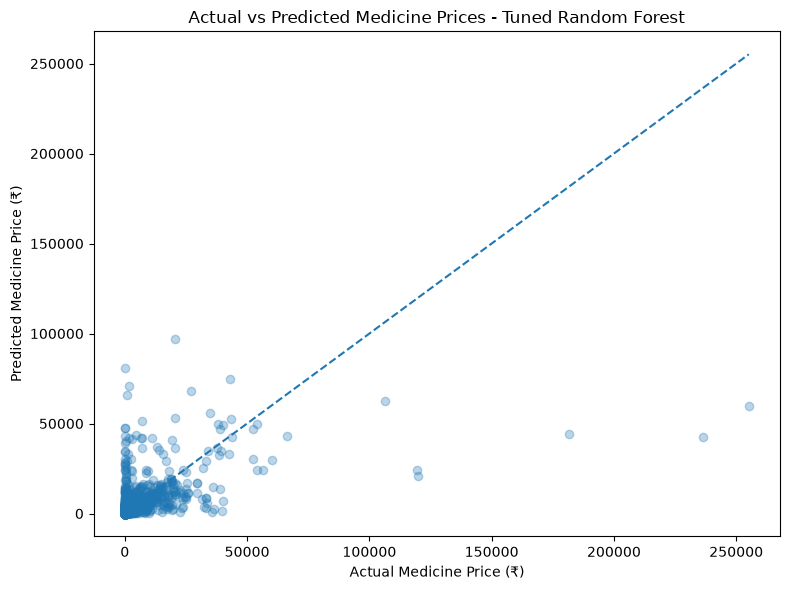

In [168]:
import matplotlib.pyplot as plt

# Actual vs Predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf_tuned,
    alpha=0.3
)

plt.xlabel("Actual Medicine Price (₹)")
plt.ylabel("Predicted Medicine Price (₹)")
plt.title("Actual vs Predicted Medicine Prices - Tuned Random Forest")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()

#### Visualize predictions using a logarithmic scale

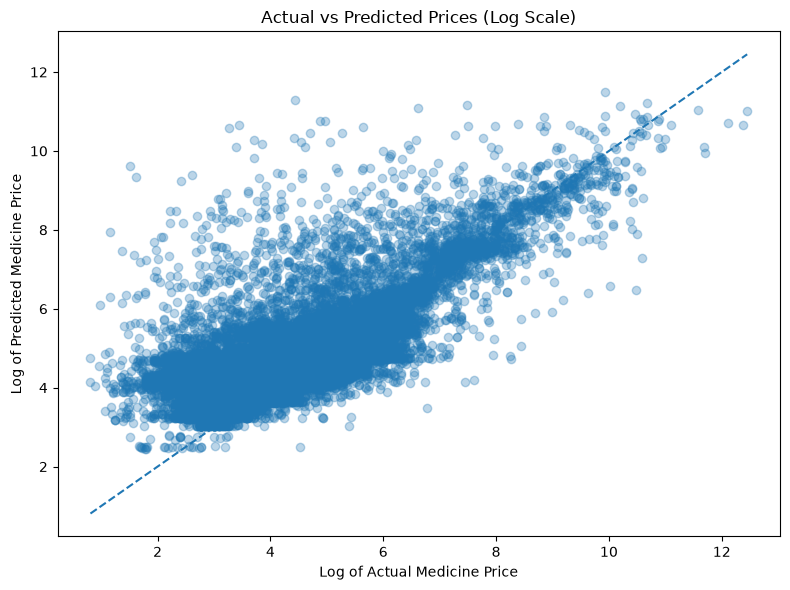

In [169]:
# Actual vs Predicted prices using log transformation

plt.figure(figsize=(8, 6))

plt.scatter(
    np.log1p(y_test),
    np.log1p(y_pred_rf_tuned),
    alpha=0.3
)

plt.xlabel("Log of Actual Medicine Price")
plt.ylabel("Log of Predicted Medicine Price")
plt.title("Actual vs Predicted Prices (Log Scale)")

# Perfect prediction reference line
min_val = min(np.log1p(y_test).min(),
              np.log1p(y_pred_rf_tuned).min())

max_val = max(np.log1p(y_test).max(),
              np.log1p(y_pred_rf_tuned).max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.tight_layout()
plt.show()

#### Analyze prediction errors

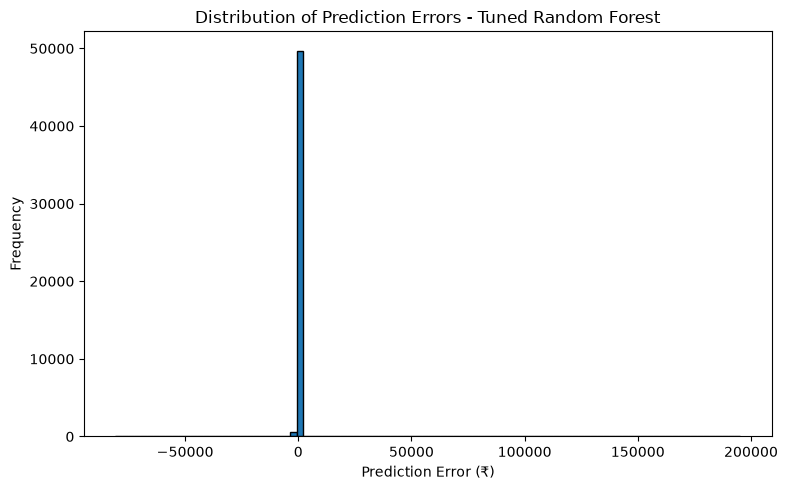

In [170]:
# Calculate prediction errors
prediction_errors = y_test - y_pred_rf_tuned

# Plot error distribution
plt.figure(figsize=(8, 5))

plt.hist(
    prediction_errors,
    bins=100,
    edgecolor="black"
)

plt.xlabel("Prediction Error (₹)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors - Tuned Random Forest")

plt.tight_layout()
plt.show()

#### Visualize the central error distribution

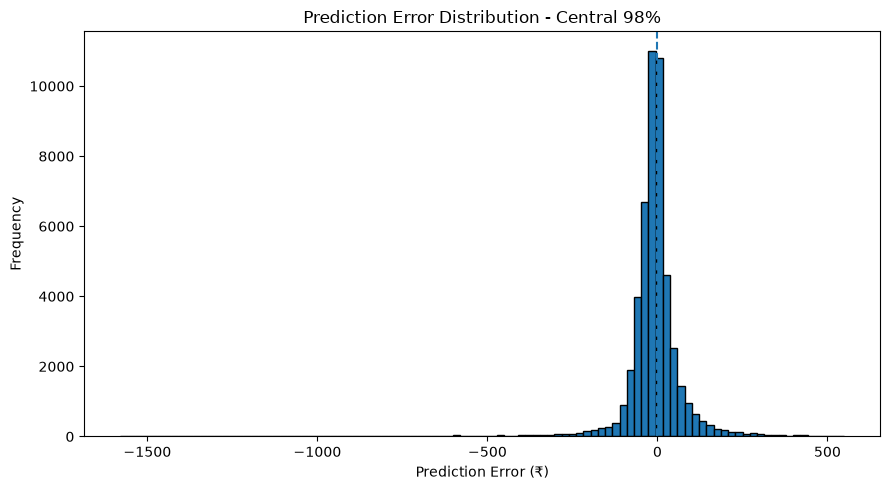

1st Percentile: -1579.3180905405463
99th Percentile: 548.1472474316594


In [171]:
# Calculate 1st and 99th percentile of prediction errors
lower_limit = prediction_errors.quantile(0.01)
upper_limit = prediction_errors.quantile(0.99)

# Plot central 98% of prediction errors
plt.figure(figsize=(9, 5))

plt.hist(
    prediction_errors,
    bins=100,
    range=(lower_limit, upper_limit),
    edgecolor="black"
)

plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Error (₹)")
plt.ylabel("Frequency")
plt.title("Prediction Error Distribution - Central 98%")

plt.tight_layout()
plt.show()

print("1st Percentile:", lower_limit)
print("99th Percentile:", upper_limit)

#### Identify the 10 medicines with the largest prediction errors

In [172]:
# Create a DataFrame for prediction analysis
prediction_analysis = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred_rf_tuned
}, index=y_test.index)

# Calculate prediction errors
prediction_analysis["Prediction Error"] = (
    prediction_analysis["Actual Price"] -
    prediction_analysis["Predicted Price"]
)

prediction_analysis["Absolute Error"] = (
    prediction_analysis["Prediction Error"].abs()
)

# Display 10 medicines with the largest prediction errors
top_10_errors = prediction_analysis.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

top_10_errors

,Actual Price,Predicted Price,Prediction Error,Absolute Error
175276,255150.00,59864.248119,195285.751881,195285.751881
115726,236500.00,42296.700085,194203.299915,194203.299915
58222,181765.00,44357.597163,137407.402837,137407.402837
238284,120000.00,21073.757055,98926.242945,98926.242945
185232,119500.00,24259.529665,95240.470335,95240.470335
104307,83.67,80857.336921,-80773.666921,80773.666921
1933,20436.19,96929.281583,-76493.091583,76493.091583
139825,1786.25,70688.024786,-68901.774786,68901.774786
94554,750.79,65981.002223,-65230.212223,65230.212223
152580,130.30,47301.276174,-47170.976174,47170.976174


#### Identify the medicines responsible

In [174]:
# Retrieve original features for the top 10 error records
top_10_features = X_test.loc[top_10_errors.index]

# Combine prediction results with original features
top_10_analysis = pd.concat(
    [top_10_errors, top_10_features],
    axis=1
)

top_10_analysis

,Actual Price,Predicted Price,Prediction Error,Absolute Error,is_discontinued,dosage_form,pack_unit,primary_ingredient,therapeutic_class,manufacturer_clean,package_type,pack_size_final,strength_value,strength_unit,strength_type,denominator_value,denominator_unit,has_denominator,strength_missing
175276,255150.00,59864.248119,195285.751881,195285.751881,False,injection,ml,Pertuzumab,other,Roche Products India Pvt Ltd,vial,14.0,30.0,mg,concentration,1.0,ml,1,0
115726,236500.00,42296.700085,194203.299915,194203.299915,False,injection,ml,Pembrolizumab,other,Msd Pharmaceuticals Pvt Ltd,vial,4.0,100.0,mg,simple,NaN,NaN,0,0
58222,181765.00,44357.597163,137407.402837,137407.402837,False,capsule,units,Acalabrutinib,other,Astrazeneca,box,12.0,100.0,mg,simple,NaN,NaN,0,0
238284,120000.00,21073.757055,98926.242945,98926.242945,False,capsule,NaN,Tafamidis,other,Pfizer Ltd,box,30.0,61.0,mg,simple,NaN,NaN,0,0
185232,119500.00,24259.529665,95240.470335,95240.470335,False,other,NaN,Casirivimab,other,Cipla Ltd,box,1.0,120.0,mg,concentration,1.0,ml,1,0
104307,83.67,80857.336921,-80773.666921,80773.666921,False,injection,NaN,Epsilon Aminocaproic Acid,other,Samarth Life Sciences Pvt Ltd,vial,1.0,500.0,mg,simple,NaN,NaN,0,0
1933,20436.19,96929.281583,-76493.091583,76493.091583,True,injection,NaN,Tocilizumab,other,Roche Products India Pvt Ltd,vial,1.0,200.0,mg,simple,NaN,NaN,0,0
139825,1786.25,70688.024786,-68901.774786,68901.774786,False,injection,NaN,Molgramostim,other,Sun Pharmaceutical Industries Ltd,vial,1.0,400.0,mg,simple,NaN,NaN,0,0
94554,750.79,65981.002223,-65230.212223,65230.212223,False,injection,NaN,Glucagon,other,Novo Nordisk India Pvt Ltd,vial,1.0,1.0,mg,simple,NaN,NaN,0,0
152580,130.30,47301.276174,-47170.976174,47170.976174,False,injection,NaN,Nitroprusside,other,Neon Laboratories Ltd,vial,1.0,50.0,mg,simple,NaN,NaN,0,0


#### Investigate the other category

In [175]:
# Analyze therapeutic class distribution
class_analysis = df["therapeutic_class"].value_counts(
    dropna=False
)

print("Therapeutic Class Distribution:")
print(class_analysis)

# Analyze price distribution by therapeutic class
class_price_analysis = (
    df.groupby("therapeutic_class")["price_inr"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values(by="median", ascending=False)
)

class_price_analysis

Therapeutic Class Distribution:
therapeutic_class
other               144119
antibiotic           30660
analgesic            24105
antacid              17432
antihistamine        13414
antidiabetic          8957
antihypertensive      7324
corticosteroid        2968
antidepressant        2499
bronchodilator        1802
diuretic               693
Name: count, dtype: int64


,count,mean,median,min,max
therapeutic_class,,,,,
other,144119,413.749735,95.000,0.00,436000.00
diuretic,693,101.110909,81.200,2.16,1018.00
antidiabetic,8957,92.677786,78.600,4.20,1920.00
antibiotic,30660,99.639244,78.000,1.32,2274.67
antihypertensive,7324,83.117041,73.325,2.33,840.38
bronchodilator,1802,67.923108,70.575,1.16,487.50
antacid,17432,81.536670,70.085,2.05,964.60
antidepressant,2499,73.629928,70.000,1.86,700.00
antihistamine,13414,71.298426,65.000,1.12,388.00


#### Investigate ingredient-level price variation

In [176]:
# Filter medicines belonging to the 'other' category
other_medicines = df[
    df["therapeutic_class"] == "other"
]

# Analyze prices by primary ingredient
ingredient_price_analysis = (
    other_medicines
    .groupby("primary_ingredient")["price_inr"]
    .agg(
        product_count="count",
        mean_price="mean",
        median_price="median",
        max_price="max"
    )
    .reset_index()
)

# Consider ingredients with at least 5 products
ingredient_price_analysis = ingredient_price_analysis[
    ingredient_price_analysis["product_count"] >= 5
]

# Display the 20 ingredients with the highest median prices
ingredient_price_analysis = ingredient_price_analysis.sort_values(
    by="median_price",
    ascending=False
)

ingredient_price_analysis.head(20)

,primary_ingredient,product_count,mean_price,median_price,max_price
1248,Ruxolitinib,5,46697.324000,43834.000,61367.00
1428,Trastuzumab,30,42464.851333,42539.740,110700.00
1358,Tenecteplase,12,39012.876667,38559.550,52799.52
158,Bevacizumab,41,35289.042195,35120.000,117625.00
1229,Rituximab,39,27593.546667,34123.300,80000.00
1116,Plerixafor,5,48682.594000,33222.970,79200.00
1212,Reteplase,6,28602.428333,30491.660,33000.00
4,Abiraterone Acetate,52,34483.385962,28720.000,150000.00
791,Ledipasvir,15,24245.958667,25000.000,27500.00
18,Adalimumab,16,22402.370000,24449.500,26000.00


#### Investigate the problematic ingredients

In [177]:
# Get ingredients from the top 10 prediction errors
error_ingredients = (
    top_10_analysis["primary_ingredient"]
    .dropna()
    .unique()
)

# Analyze these ingredients in the complete dataset
error_ingredient_analysis = (
    df[df["primary_ingredient"].isin(error_ingredients)]
    .groupby("primary_ingredient")["price_inr"]
    .agg(
        product_count="count",
        mean_price="mean",
        median_price="median",
        min_price="min",
        max_price="max"
    )
    .reset_index()
    .sort_values("product_count")
)

error_ingredient_analysis

,primary_ingredient,product_count,mean_price,median_price,min_price,max_price
0,Acalabrutinib,1,181765.000000,181765.000,181765.00,181765.00
1,Casirivimab,1,119500.000000,119500.000,119500.00,119500.00
6,Pembrolizumab,1,236500.000000,236500.000,236500.00,236500.00
7,Pertuzumab,1,255150.000000,255150.000,255150.00,255150.00
8,Tafamidis,1,120000.000000,120000.000,120000.00,120000.00
4,Molgramostim,2,4143.125000,4143.125,1786.25,6500.00
3,Glucagon,3,918.596667,990.000,750.79,1015.00
2,Epsilon Aminocaproic Acid,3,91.706667,83.670,48.70,142.75
5,Nitroprusside,3,142.933333,141.500,130.30,157.00
9,Tocilizumab,3,25605.363333,20436.190,8112.00,48267.90


#### Identify unseen ingredients

In [178]:
# Identify unique ingredients in training and testing data

train_ingredients = set(
    X_train["primary_ingredient"].dropna().unique()
)

test_ingredients = set(
    X_test["primary_ingredient"].dropna().unique()
)

# Ingredients present in test but absent in training
unseen_ingredients = test_ingredients - train_ingredients

print("Unique ingredients in training:", len(train_ingredients))
print("Unique ingredients in testing:", len(test_ingredients))
print("Unseen ingredients in testing:", len(unseen_ingredients))

Unique ingredients in training: 1532
Unique ingredients in testing: 1172
Unseen ingredients in testing: 54


In [179]:
# Identify test records containing unseen ingredients

unseen_mask = (
    X_test["primary_ingredient"].notna() &
    ~X_test["primary_ingredient"].isin(train_ingredients)
)

print("Test records with unseen ingredients:", unseen_mask.sum())

print(
    "Percentage of test records affected:",
    round(unseen_mask.mean() * 100, 2), "%"
)

# Display some examples
X_test.loc[
    unseen_mask,
    [
        "primary_ingredient",
        "manufacturer_clean",
        "dosage_form",
        "therapeutic_class"
    ]
].head(20)

Test records with unseen ingredients: 66
Percentage of test records affected: 0.13 %


,primary_ingredient,manufacturer_clean,dosage_form,therapeutic_class
186441,Idoxuridine,Bell Pharma Pvt Ltd,drops,other
178386,Pazufloxazin,Zydus Cadila,other,other
151419,Nitroprusside,Samarth Life Sciences Pvt Ltd,injection,other
186935,charcoal,Taurus Laboratories Pvt Ltd,tablet,other
233750,Ichthyol Pale,Systopic Laboratories Pvt Ltd,cream,other
121006,Insulin detemir,Novo Nordisk India Pvt Ltd,injection,other
6046,Maraviroc,Emcure Pharmaceuticals Ltd,tablet,other
115740,Ribociclib,Novartis India Ltd,tablet,other
179249,Propyl paraben,Mankind Pharma Ltd,gel,other
34494,Human Papillomavirus Bivalent Vaccine,Glaxo Smithkline Pharmaceuticals Ltd,injection,other


#### Next: Compare prediction errors
Let's compare the tuned Random Forest's performance on:
1. Test records with ingredients seen during training.
2. Test records with ingredients not seen during training.

In [180]:
# Compare prediction errors for seen and unseen ingredients

comparison_df = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred_rf_tuned,
    "ingredient_status": np.where(
        unseen_mask,
        "Unseen ingredient",
        "Seen ingredient"
    )
})

comparison_df["absolute_error"] = abs(
    comparison_df["actual"] - comparison_df["predicted"]
)

comparison = comparison_df.groupby("ingredient_status").agg(
    records=("actual", "count"),
    MAE=("absolute_error", "mean"),
    RMSE=("absolute_error", lambda x: np.sqrt(
        np.mean(x ** 2)
    ))
)

comparison

,records,MAE,RMSE
ingredient_status,,,
Seen ingredient,50729,150.525945,1274.28574
Unseen ingredient,66,20043.983305,45047.45266


##### Identify the medicines causing these errors

In [181]:
# Analyze prediction errors for unseen ingredients

unseen_error_analysis = X_test.loc[
    unseen_mask,
    [
        "primary_ingredient",
        "manufacturer_clean",
        "dosage_form",
        "therapeutic_class"
    ]
].copy()

unseen_error_analysis["actual_price"] = y_test.loc[unseen_mask]

unseen_error_analysis["predicted_price"] = pd.Series(
    y_pred_rf_tuned,
    index=y_test.index
).loc[unseen_mask]

unseen_error_analysis["absolute_error"] = abs(
    unseen_error_analysis["actual_price"] -
    unseen_error_analysis["predicted_price"]
)

# Display the 20 records with the highest prediction errors
unseen_error_analysis.sort_values(
    by="absolute_error",
    ascending=False
).head(20)

,primary_ingredient,manufacturer_clean,dosage_form,therapeutic_class,actual_price,predicted_price,absolute_error
175276,Pertuzumab,Roche Products India Pvt Ltd,injection,other,255150.00,59864.248119,195285.751881
115726,Pembrolizumab,Msd Pharmaceuticals Pvt Ltd,injection,other,236500.00,42296.700085,194203.299915
58222,Acalabrutinib,Astrazeneca,capsule,other,181765.00,44357.597163,137407.402837
238284,Tafamidis,Pfizer Ltd,capsule,other,120000.00,21073.757055,98926.242945
185232,Casirivimab,Cipla Ltd,other,other,119500.00,24259.529665,95240.470335
104307,Epsilon Aminocaproic Acid,Samarth Life Sciences Pvt Ltd,injection,other,83.67,80857.336921,80773.666921
152580,Nitroprusside,Neon Laboratories Ltd,injection,other,130.30,47301.276174,47170.976174
177603,Nitroprusside,Troikaa Pharmaceuticals Ltd,injection,other,141.50,47301.276174,47159.776174
42087,Carbenicillin,Lyka Labs,injection,other,25.00,39333.920884,39308.920884
72923,Aflibercept,Bayer Zydus Pharma Pvt Ltd,injection,other,56693.00,24279.472990,32413.527010


##### How much do these records contribute to total prediction error?

In [182]:
# Calculate contribution of unseen ingredients to total error

total_absolute_error = comparison_df["absolute_error"].sum()

unseen_absolute_error = comparison_df.loc[
    comparison_df["ingredient_status"] == "Unseen ingredient",
    "absolute_error"
].sum()

seen_absolute_error = total_absolute_error - unseen_absolute_error

print("Total absolute error:", round(total_absolute_error, 2))

print("Seen ingredient error:", round(seen_absolute_error, 2))

print("Unseen ingredient error:", round(unseen_absolute_error, 2))

print(
    "Percentage of total error from unseen ingredients:",
    round((unseen_absolute_error / total_absolute_error) * 100, 2),
    "%"
)

Total absolute error: 8958933.54
Seen ingredient error: 7636030.65
Unseen ingredient error: 1322902.9
Percentage of total error from unseen ingredients: 14.77 %


#### Investigate errors for seen ingredients
Now let's examine the 20 worst predictions among ingredients that the model has already encountered during training.

In [183]:
# Analyze prediction errors for seen ingredients

seen_mask = ~unseen_mask

seen_error_analysis = X_test.loc[
    seen_mask,
    [
        "primary_ingredient",
        "manufacturer_clean",
        "dosage_form",
        "therapeutic_class"
    ]
].copy()

seen_error_analysis["actual_price"] = y_test.loc[seen_mask]

seen_error_analysis["predicted_price"] = pd.Series(
    y_pred_rf_tuned,
    index=y_test.index
).loc[seen_mask]

seen_error_analysis["absolute_error"] = abs(
    seen_error_analysis["actual_price"] -
    seen_error_analysis["predicted_price"]
)

# Display the 20 highest-error records
seen_error_analysis.sort_values(
    by="absolute_error",
    ascending=False
).head(20)

,primary_ingredient,manufacturer_clean,dosage_form,therapeutic_class,actual_price,predicted_price,absolute_error
1933,Tocilizumab,Roche Products India Pvt Ltd,injection,other,20436.19,96929.281583,76493.091583
139825,Molgramostim,Sun Pharmaceutical Industries Ltd,injection,other,1786.25,70688.024786,68901.774786
94554,Glucagon,Novo Nordisk India Pvt Ltd,injection,other,750.79,65981.002223,65230.212223
40973,Flucytosine,Jolly Healthcare,tablet,other,7000.00,51434.041896,44434.041896
48988,Crizotinib,Pfizer Ltd,capsule,other,106270.25,62759.679328,43510.570672
136271,Psoralen,Pfizer Ltd,tablet,other,30.46,43047.739767,43017.279767
11129,Abiraterone Acetate,Medicamen Biotech Ltd,tablet,other,27000.00,68351.119447,41351.119447
150344,Carbimazole,Abbott,tablet,other,282.06,40334.542573,40052.482573
25748,Saroglitazar,Zydus Cadila,tablet,other,1808.00,41720.935596,39912.935596
199997,Dolutegravir,Emcure Pharmaceuticals Ltd,tablet,other,4388.50,43479.158525,39090.658525


#### Check how frequently these ingredients occur in training
An ingredient can technically be present in training but have only one or two examples. That may not be enough for the model to learn a reliable pricing pattern.

Let's investigate the training frequency of the 20 ingredients with the highest errors.

In [184]:
# Check training frequency of high-error ingredients

ingredient_frequency = (
    X_train["primary_ingredient"]
    .value_counts()
    .rename("training_records")
)

seen_error_frequency = (
    seen_error_analysis
    .sort_values("absolute_error", ascending=False)
    .head(20)
    .copy()
)

seen_error_frequency["training_records"] = (
    seen_error_frequency["primary_ingredient"]
    .map(ingredient_frequency)
)

seen_error_frequency[
    [
        "primary_ingredient",
        "actual_price",
        "predicted_price",
        "absolute_error",
        "training_records"
    ]
]

,primary_ingredient,actual_price,predicted_price,absolute_error,training_records
1933,Tocilizumab,20436.19,96929.281583,76493.091583,2
139825,Molgramostim,1786.25,70688.024786,68901.774786,1
94554,Glucagon,750.79,65981.002223,65230.212223,2
40973,Flucytosine,7000.00,51434.041896,44434.041896,4
48988,Crizotinib,106270.25,62759.679328,43510.570672,1
136271,Psoralen,30.46,43047.739767,43017.279767,2
11129,Abiraterone Acetate,27000.00,68351.119447,41351.119447,42
150344,Carbimazole,282.06,40334.542573,40052.482573,15
25748,Saroglitazar,1808.00,41720.935596,39912.935596,1
199997,Dolutegravir,4388.50,43479.158525,39090.658525,3


#### Investigate price variation within ingredients

In [185]:
# Analyze training price distribution of problematic ingredients

problem_ingredients = (
    seen_error_frequency["primary_ingredient"]
    .dropna()
    .unique()
)

train_price_analysis = X_train.loc[
    X_train["primary_ingredient"].isin(problem_ingredients),
    ["primary_ingredient", "manufacturer_clean", "dosage_form"]
].copy()

# Attach actual training prices
train_price_analysis["price_inr"] = y_train.loc[
    train_price_analysis.index
]

# Calculate price statistics for each ingredient
ingredient_price_summary = (
    train_price_analysis
    .groupby("primary_ingredient")["price_inr"]
    .agg(
        training_records="count",
        mean_price="mean",
        median_price="median",
        min_price="min",
        max_price="max",
        std_price="std"
    )
    .sort_values("std_price", ascending=False)
)

ingredient_price_summary

,training_records,mean_price,median_price,min_price,max_price,std_price
primary_ingredient,,,,,,
Dasatinib,35,19453.838857,5400.000,1095.00,211538.51,48131.132063
Bevacizumab,31,34629.482581,27990.000,6993.00,117625.00,29291.408851
Tocilizumab,2,28189.950000,28189.950,8112.00,48267.90,28394.509195
Abiraterone Acetate,42,36457.394524,29200.000,9975.00,150000.00,27943.818986
Trastuzumab,22,45966.231818,56425.000,10800.00,110700.00,25093.015890
Leuprolide,49,9321.322857,8841.000,172.11,36357.00,8284.529778
Erlotinib,35,9667.741429,7775.000,800.00,35450.00,7923.045159
Flucytosine,4,4517.250000,1584.500,1400.00,13500.00,5989.798849
Fludarabine,7,7722.597143,6500.000,5557.68,11825.50,2460.397523


### Let's inspect your FrequencyEncoder

In [186]:
from sklearn.preprocessing import OneHotEncoder

# Final conclusions
1. The tuned Random Forest is our preferred model among the experiments conducted.
2. Ingredient combination engineering provided a modest improvement.
3. Log transformation reduced MAE but worsened RMSE and R².
4. The model performs better on lower-priced medicines.
5. Generalization to unseen manufacturers is more challenging, particularly for expensive medicines.
6. Extreme price values have a substantial influence on RMSE.